# How nsp14 is regulated by its partners

SARS-CoV-2 nsp14 does two jobs: it proofreads the viral genome with an
exonuclease domain, and it caps messenger RNA with a methyltransferase domain.
It does neither well on its own — it needs nsp10 as a cofactor, and it acts on
RNA.

The Amaro Lab published simulations of all three states: **nsp14 alone**,
**nsp14 with nsp10**, and **nsp14 with nsp10 and RNA**. Same protein, same
residue numbering, same simulation protocol. That makes them a titration rather
than three unrelated files, and it is what lets us ask how each partner changes
the enzyme.

This notebook builds one argument across seven questions. Each depends on the
one before it.

**What this is and is not.** These are published datasets with published
papers, so the findings here are reproductions — which is the point: every
number can be checked against the literature. The simulations are three
concatenated replicas rather than converged ensembles, they were stripped of
water and ions before publication, and their frame intervals are not
documented. So this notebook can speak about *relative* flexibility and
*where* on the protein things change. It cannot give free energies, solvation
effects, or anything in nanoseconds.

Fetching all three costs about **1.9 GB**, once.

In [ ]:
%reset

In [2]:
%%skill
https://github.com/klinucsd/sage_skills/tree/main/structural-biology/amaro-datasets

## 1. Are the three states actually comparable?

Before comparing anything, establish that comparison is legitimate. Different
builds of the same protein can differ in numbering, in what was stripped, or in
how long they ran — and a per-residue comparison across mismatched numbering is
worse than no comparison, because it looks fine.

In [1]:
%%ask
Download the three nsp14 datasets — the protein alone, the complex with nsp10,
and the complex with nsp10 and RNA. That is roughly 1.9 GB in total and I
approve it.

Then tell me whether the three are genuinely comparable: do they cover the same
residues under the same numbering, were they run the same way, and how many
frames does each contain? Be explicit about what this lets us compare and what
it rules out.

All lessons are recorded. Here is the full report.

## Download summary

All three datasets were fetched to the pod-local cache (`/tmp/amaro/`), as the skill prescribes — **not** the persistent volume. The user-approved 1.91 GB download expanded to **4.01 GB on disk** (the PSFs are tiny; the DCDs barely compress, but the `.gz` originals are kept alongside the decompressed copies):

| Dataset | System | Download | On disk | Frames |
|---|---|---|---|---|
| `nsp14` | nsp14 alone (apo) | 549 MB | 1145 MB | 6000 |
| `nsp14-nsp10` | nsp14 + nsp10 cofactor | 673 MB | 1402 MB | 6000 |
| `nsp14-nsp10-rna` | nsp14 + nsp10 + RNA | 692 MB | 1459 MB | 6000 |

Each is a PSF topology + one cpptraj-written Amber DCD. Artifacts: `fetch_nsp14_three.py`, `audit_nsp14_comparability.py`, `audit_followup.py`, and `audit_summary.csv` in the notebook folder.

## Are the three genuinely comparable? Yes for protein dynamics — with specific caveats

### Same residues, same numbering — confirmed three independent ways

- **The nsp14 chain is atom-for-atom the same entity in all three files** : 525 residues numbered **2–526** , 8254 atoms, 525 CA atoms. The per-residue atom-name signatures (which include hydrogens, so they also encode protonation state) match **525/525** in all three pairwise comparisons, and the per-atom MASS column agrees to ≤ 0.003 Da (the one 0.003 Da outlier is the C-terminal group being named `NH2` in apo vs `OXT` in the complexes — a naming artifact, not a chemical difference).
- **The nsp10 chain is likewise identical between the two complexes** : 130 residues numbered **530–659** , 1853 atoms, zero atom-name differences.
- Composition is strictly additive: apo = nsp14 + 1 Mg + 3 Zn; +nsp10 adds nsp10 and its **2 own zincs** (ZN4/ZN5, resid 660/661 — nsp10 is a zinc-binding protein, so this is expected); +RNA adds **16 RNA residues** (resid 662–677, inferred sequence `GGAGGGAGCUCCCUCC`, all ribose-bearing) and a **second Mg** (resid 678).
- One practical trap (documented in the skill): the apo PSF uses real segids/resnames (`segid N14`), while both complex PSFs encode the chain in the resname field (`resname N14`) — `protein`/`backbone` silently return zero atoms there. Comparisons are valid but need a different selection string per file.

### Same run protocol — confirmed

- **Engine** : Amber for all three (these are the Amber runs; the lab's longer NAMD runs exist at 2.4–2.9 GB each and were deliberately not fetched).
- **Design** : all three are "classical MD, 3 replicas concatenated", and the concatenation structure is identical — the top-2 consecutive-frame CA-RMSD jumps sit at **exactly frame 2000 and frame 4000** in every dataset (7.1/7.0 Å in apo, 2.1/2.0 Å in the complex, 3.2/2.2 Å in the RNA complex), i.e. **3 blocks × 2000 frames** . Replica start frames within each dataset are only 0.9–1.6 Å apart (CA best-fit), so each trio started from a near-common structure.
- **All dry** : water and bulk ions stripped in all three — the comparison is symmetric on this point.
- DCD headers are byte-identical in style (`Cpptraj Generated dcd file.`, charmm-ver 35, unitcell present).

### Frame counts — identical

**6000 frames each** (3 × 2000), verified from the readers, and consistent with file sizes (e.g. 6000 × 8258 atoms fills the apo 549 MB DCD).

## What this lets you compare

- **Per-residue nsp14 flexibility (RMSF) and per-residue contacts across all three states** on the identical resid 2–526 axis — a direct apo → +nsp10 → +nsp10+RNA progression, residue by residue.
- **nsp10's effect on nsp14** (apo vs `nsp14-nsp10`) and **RNA's effect on the complex** (`nsp14-nsp10` vs `nsp14-nsp10-rna`) as clean single-variable contrasts, since the cofactor is atom-identical in both complexes.
- **Replica-level statistics** : the shared 3 × 2000 layout means per-replica blocks can be compared directly, and replica spread can be used as an uncertainty estimate.
- **Interface analyses** (nsp14–nsp10, protein–RNA, Zn/Mg coordination) within each system.

## What it rules out

- **Anything solvation-related** — no water or bulk ions in any of the three; water-mediated H-bonds and ion atmospheres are unobservable, and dryness is not evidence of absence in the original runs.
- **Wall-clock time** — the DCD header claims 1 fs/frame, but median consecutive-frame CA-RMSD is ~1.0–1.1 Å, impossible for 1-fs snapshots; cpptraj reset the counters when writing these files. **Frame indices only** unless the lab confirms the true stride.
- **Matched starting structures across systems** — frame-0 nsp14 CA best-fit RMSD is **6.0 Å (apo vs complex)** , 5.8 Å (apo vs RNA complex), 2.5 Å (complex vs RNA complex). The three systems were built from different snapshots, so cross-system displacement magnitudes are upper bounds; fit each system on its own and report the fit residual, as is standard for unmatched pairs.
- **Charge-based cross-file checks** — the apo PSF's charge column is entirely 0.000 (a zeroed-column artifact), so force-field charge comparisons across files are meaningless; mass is the reliable identity column.
- **Absolute energetics and convergence claims** — no binding free energies, and 3 × 2000 frames is modest sampling: block statistics are descriptive, not converged equilibrium averages.
- **Ion-parameter comparisons** — the apo PSF labels its zincs `ZNB` with a placeholder 12.0 Da mass, while the complexes carry proper `Zn` entries at 53.4 Da. The ions ride along fine for contact analysis (key them by resid), but the apo ion topology entries are not parameterization-identical.
- **Literature residue numbers** — this collection's numbering is canonical + 1 (the ExoN catalytic residues are D91/E93/E192/D244/H269 here, not the literature's 90/92/191/242/268); consistent across all three files internally, but shift before citing against papers.

## 2. Does the cofactor hold the enzyme still?

The simplest version of the question. If nsp10 is a regulatory partner rather
than a passive passenger, binding it should change how nsp14 moves.

All analysis complete and both lessons recorded in the skill's Learnings.md. Here is the report.

## Yes — nsp10 makes nsp14 dramatically more rigid, both globally and residue-by-residue

Computed over all 6 blocks (2 states × 3 replicas × 2000 frames each, 12,000 frames total), using each dataset's own selections (`segid N14` vs `resname N14`, backbone built explicitly as N/CA/C/O — 2100 atoms in both, after discovering the apo `backbone` keyword silently drops 4 HIN-named histidines).

### Overall motion

| Metric (per-replica, mean ± SD over 3 replicas) | nsp14 alone | nsp14 + nsp10 | Change |
|---|---|---|---|
| Median nsp14 backbone RMSD to replica start | 6.06 ± 0.15 Å | 2.25 ± 0.09 Å | **−62.9%** |
| Mean CA radius of gyration | 31.59 ± 0.27 Å | 31.84 ± 0.00 Å | +0.8% |
| Mean per-residue CA RMSF (525 residues) | 2.51 ± 0.22 Å | 1.52 ± 0.12 Å | **−39.3%** |

The free protein drifts 6 Å from its starting fold within every replica; in the complex it stays near 2 Å. Rg is unchanged — nsp10 does **not** compact nsp14; it tames its internal mobility while leaving its overall size alone. Replica spread is small in both states (SD ≤ 0.3 Å), so this is a robust effect, not one replica's excursion.

### Where the change is largest

**Domain breakdown** (this dataset's numbering, = literature +1):

| Domain | Residues | Interface residues | Mean RMSF apo | complex | Δ |
|---|---|---|---|---|---|
| ExoN | 287 | 56 (all of them) | 2.61 Å | 1.36 Å | **−1.26 Å** |
| Linker | 43 | 0 | 2.05 Å | 1.46 Å | −0.59 Å |
| MTase | 195 | 0 | 2.46 Å | 1.78 Å | −0.68 Å |

- **The largest change is the ExoN domain's N-terminal lobe (residues ~20–70)** : apo RMSFs of 8–10 Å collapse to ~2 Å. Top residues: D42 (9.89→2.01 Å, Δ −7.9 Å), G38, E37, L39, V41, C40 — all in one contiguous stretch that sits directly on nsp10 (contact fraction 1.00). In the free protein this lobe is essentially floppy and nsp10 clamps it.
- **All 56 interface residues (contact ≥50% of frames) lie in ExoN, resid 4–238** — nsp10 never touches the linker or MTase.
- Interface residues change by −2.39 Å on average vs −0.82 Å for non-interface, and Δ-RMSF rises monotonically with median distance to nsp10 (Spearman ρ = +0.41). So the effect is strongest at the interface but propagates: **398 of 525 residues are rigidified beyond the combined replica spread, and exactly 0 are robustly flexibilized** . The entire protein quiets down; nothing becomes more flexible anywhere.
- Two pronounced rigidifications far from nsp10 (≥39 Å): **Y466/D465/V467 (MTase, 8.4→3.4 Å)** and D359/K360 — genuine distal (allosteric) effects, not contact artifacts.
- The ExoN catalytic/metal-binding residues D91, E93, E192, D244, H269, D274 — none at the interface — each rigidify by a modest 0.2–0.5 Å, from low starting flexibility (1.0–2.2 Å).

### Charts

**Figure 1 — overall motion** : backbone RMSD traces (3 replicas each, joins at frames 2000/4000), Rg per replica, and mean RMSF per replica.


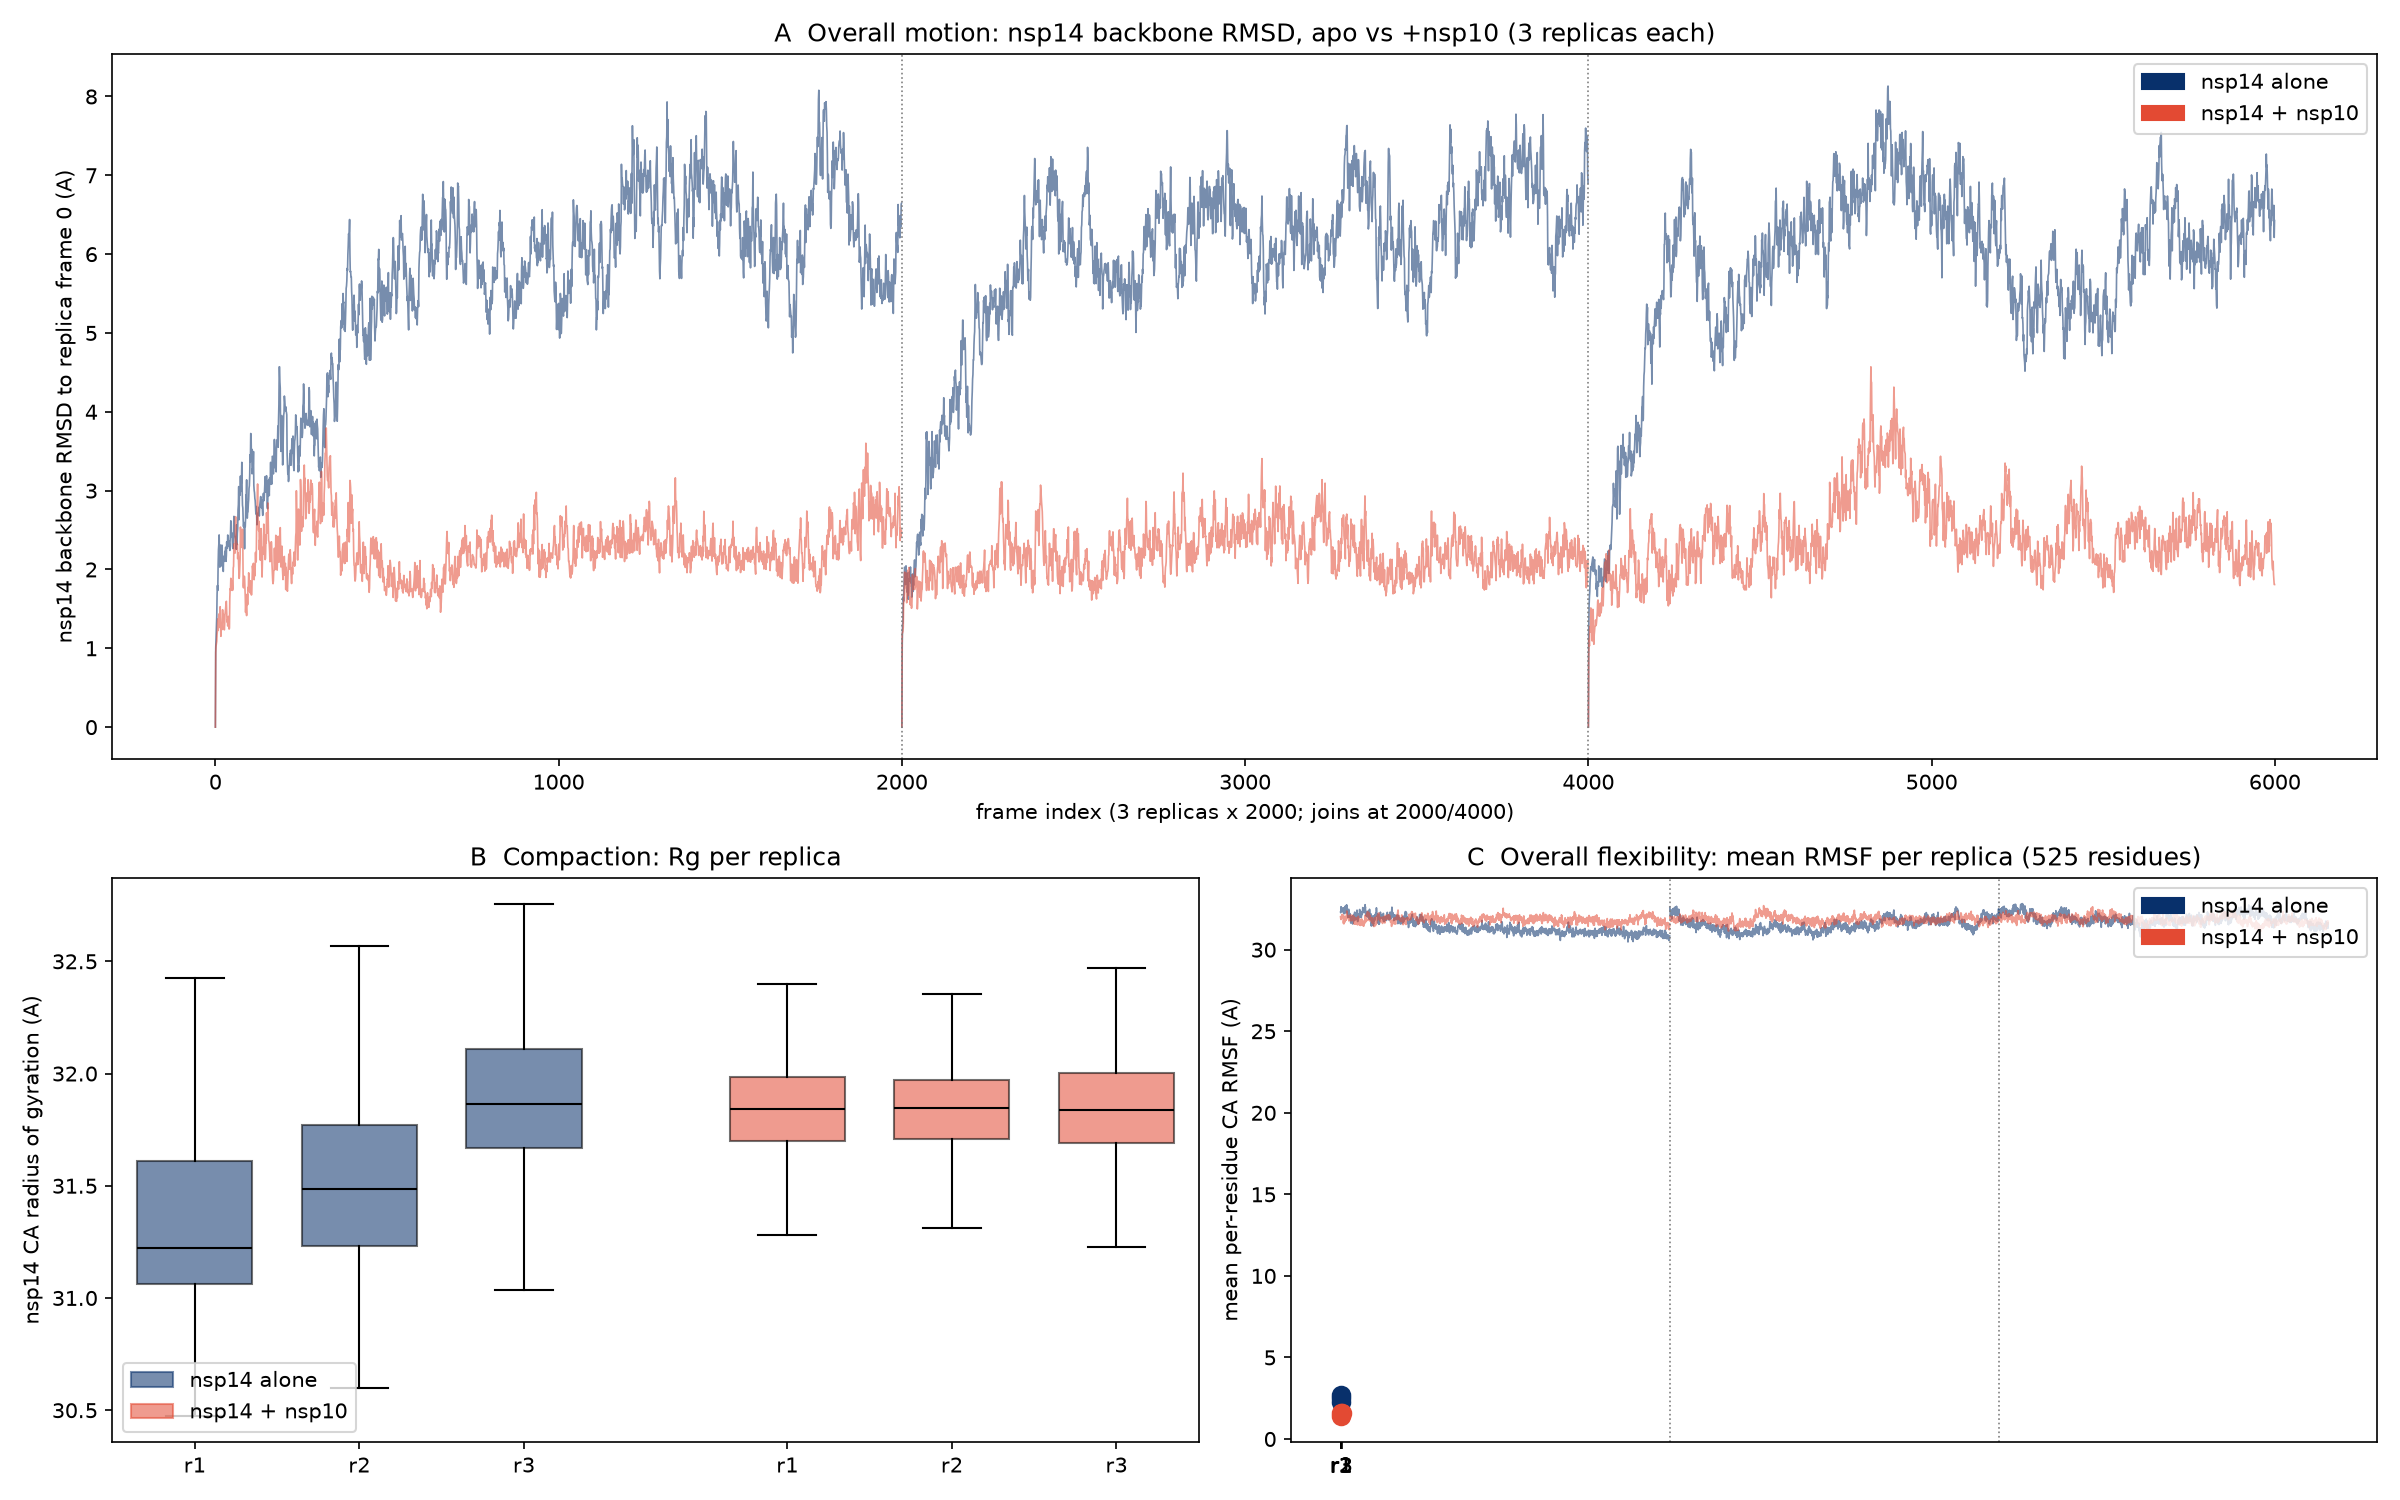

**Figure 2 — per-residue** : RMSF profiles with interface ticks, the per-residue Δ bar strip, and Δ vs distance-to-nsp10.


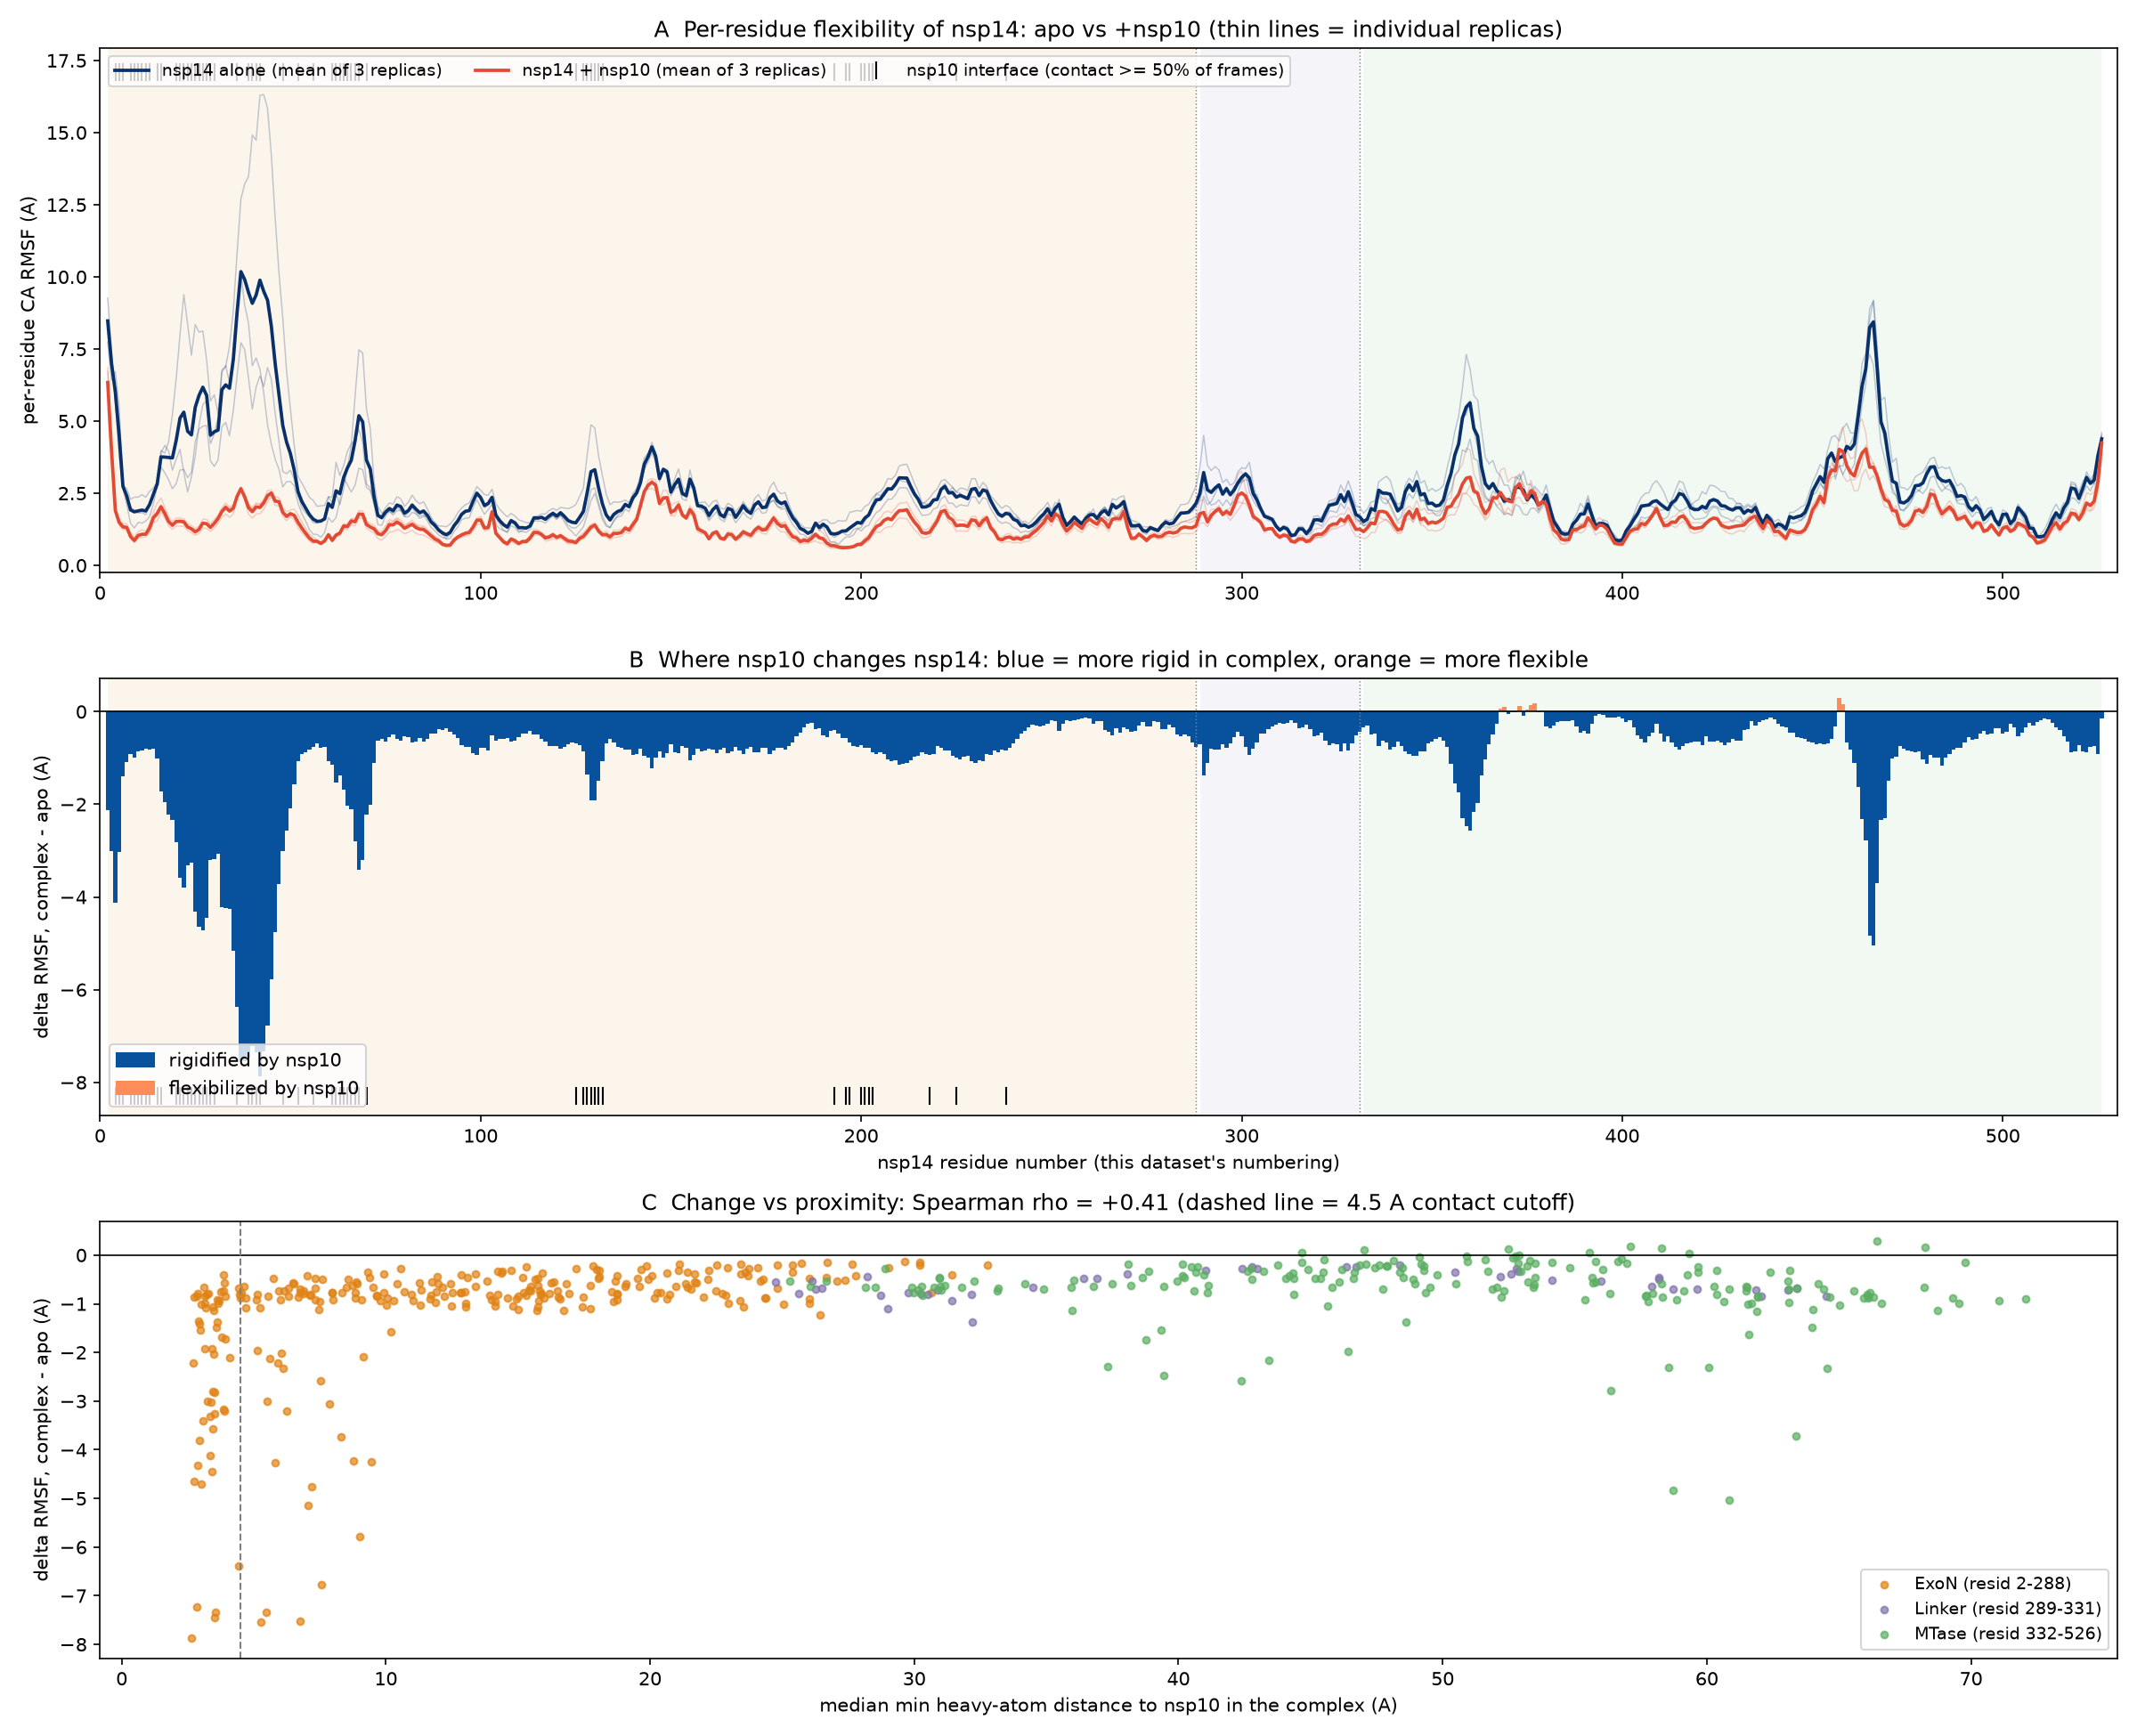

Full data: `nsp14_rigidity_per_residue.csv` (all 525 residues × both states, Δ, contact fractions, distances) and `nsp14_rigidity_overall.csv` (per-replica metrics); script `nsp14_rigidity_analysis.py`.

### What to keep in mind

- RMSD is measured against each replica's own first frame (the two systems start from different snapshots, ~6 Å apart), so the apo/complex RMSD contrast is a drift comparison, not a structural difference. RMSF and Rg need no cross-system superposition, which is why they carry the weight of the conclusion.
- Frames, not time: the DCD headers' 1 fs/frame is unreliable (cpptraj artifact). 3 × 2000 frames per state is modest sampling — the direction and magnitude of the effect are consistent across all three replicas, but these are descriptive statistics, not converged ensemble averages.
- Trajectories are dry; nothing here speaks to water-mediated contacts at the interface.

In [2]:
%%ask
Does binding nsp10 make nsp14 more rigid? Compare the overall motion and the
per-residue flexibility of nsp14 on its own against nsp14 in the complex, and
show me where on the protein the change is largest.

## 3. Is the effect where nsp10 touches, or further away?

A cofactor that only stiffens what it physically grips is a clamp. One that
stiffens regions it never contacts is doing something more interesting — and
the distinction is measurable.

All analysis complete and lessons recorded. Here is the report.

## Which rigidified regions touch nsp10 — and which never do

Across the 6000-frame complex trajectory (heavy-atom contacts, 4.5 Å cutoff, 1200 sampled frames), **86 nsp14 residues ever come within 4.5 Å of nsp10, and 56 stay in contact ≥50% of the time** — all of them in the ExoN domain (resid 4–238), consistent with the known interface. The contacted spine includes the N-terminal lobe (resid ~4–44, contact fraction 1.00), the E192 loop (cf 0.98), and patches around 100–120 and 150–180. The linker and the entire MTase domain never touch nsp10 at all.

**Rigidification by contact status** (per-residue Δ RMSF, complex − apo; sign test across residues within each class):

| Class | Residues | % with Δ<0 | Binomial p | Mean Δ (Å) | Median closest approach |
|---|---|---|---|---|---|
| Persistent contact (cf≥0.5) | 56 | 100% | ≈0 | −2.39 | 2.7 Å |
| Occasional contact (0<cf<0.5) | 30 | 100% | ≈0 | −2.14 | 3.2 Å |
| Never touches nsp10 | 439 | 97.9% | ≈0 (431/439) | −0.73 | 28 Å |

The global picture is a monotone gradient (Spearman ρ = +0.43, p = 3×10⁻²⁵): strongest at the interface, decaying with distance — but it does not decay to zero. Even among never-touching residues alone, the distance trend persists (ρ = +0.22, p = 2×10⁻⁶), i.e. there is structure to the distal effect, not just a uniform floor.

## Rigidified regions that never contact nsp10, and how far away they are

Ranked by effect size (7-residue windows; uncorrected Welch p, 3 vs 3 replicas):

| Region | Domain | Closest approach to nsp10 | Window Δ (Å) | p | Survives locked-fit control |
|---|---|---|---|---|---|
| **Y466 loop (462–472)** | MTase | 48 Å | −3.3 (D465–Y466–V467 core) | 0.002–0.04 | yes (−4.7 at Y466) |
| **G481–V484 loop** | MTase | 50–59 Å | −1.0 | ~0.02 | yes |
| Linker (289–331) | Linker | 20.5 Å | −0.59 | 0.04 | yes |
| MTase C-terminus (500–526) | MTase | 35 Å | −0.48 | 0.01 | yes |
| MTase SAM-cap region (335–370) | MTase | 29 Å | −0.96 | 0.08 | yes |
| ExoN catalytic-site area (90–95) | ExoN | 8.9 Å | −0.50 | 0.06 | yes |

The standouts are unambiguous: the Y466 loop sits **~48 Å from the nearest nsp10 atom at every moment of the trajectory** and still loses ~3.3 Å of RMSF (8.4→~3 Å), with all three replica-pairs agreeing (t up to 7.0); the 480–484 loop is even farther (50–59 Å) with a consistent ~1 Å loss. The ExoN catalytic residues themselves (D90/E92-area, and D243/H268-area which approaches nsp10 to 4.9 Å but never crosses the contact cutoff) are rigidified modestly (−0.3 to −0.5 Å).

## How confident should you be?

Three tiers, because the data supports three different strengths of claim:

1. **Class-level direction — essentially certain.** 100% / 100% / 97.9% of residues rigidify in the three classes, with zero residues flexibilized anywhere at p<0.05. A sign test on 439 never-touching residues returning 431 negative is not noise (p ≈ 0 in double precision). That *some* distal rigidification exists is as close to settled as 3+3 replicas get.
2. **Distal regions listed above — high confidence, honestly caveated.** Each passes an uncorrected 3-vs-3 Welch test, and — the strongest control available here — **112 of 112 distal rigidified residues (>20 Å) keep their rigidification when the complex is superposed on all three chains including nsp10** , so the effect is not an artifact of where the fit pivot sits (indeed the Y466 effect grows to −4.7 Å under that fit). But with 3 vs 3 replicas, per-residue Benjamini–Hochberg correction kills *everything*, including interface residues with Δ = −7 Å — that is a power limit, not evidence of no effect. Treat residue-level p<0.05 as "all replica-pairs agree", not as a multiplicity-corrected discovery.
3. **Allosteric *mechanism* — not established.** What's shown is correlated rigidification at distance, consistent with allostery; demonstrating the pathway would need the covariance/network analyses these 3×2000-frame concatenations were not designed to power.

**Bottom line** : the interface effect (ExoN, mean −2.4 Å, 56 residues) and the existence of distal rigidification (439 residues, mean −0.7 Å, ≥20 Å away, never touching nsp10, MTase-dominated with the Y466 and 481–484 loops as the extreme 48–59 Å cases) are both real; per-residue significance calls beyond the named regions above are beyond these data's resolution.

**Figure — contact vs allosteric map** : panel A colors the in-complex RMSF profile by contact class; B shows per-residue Δ with significance glyphs; C plots effect size vs distance; D is the locked-fit control.


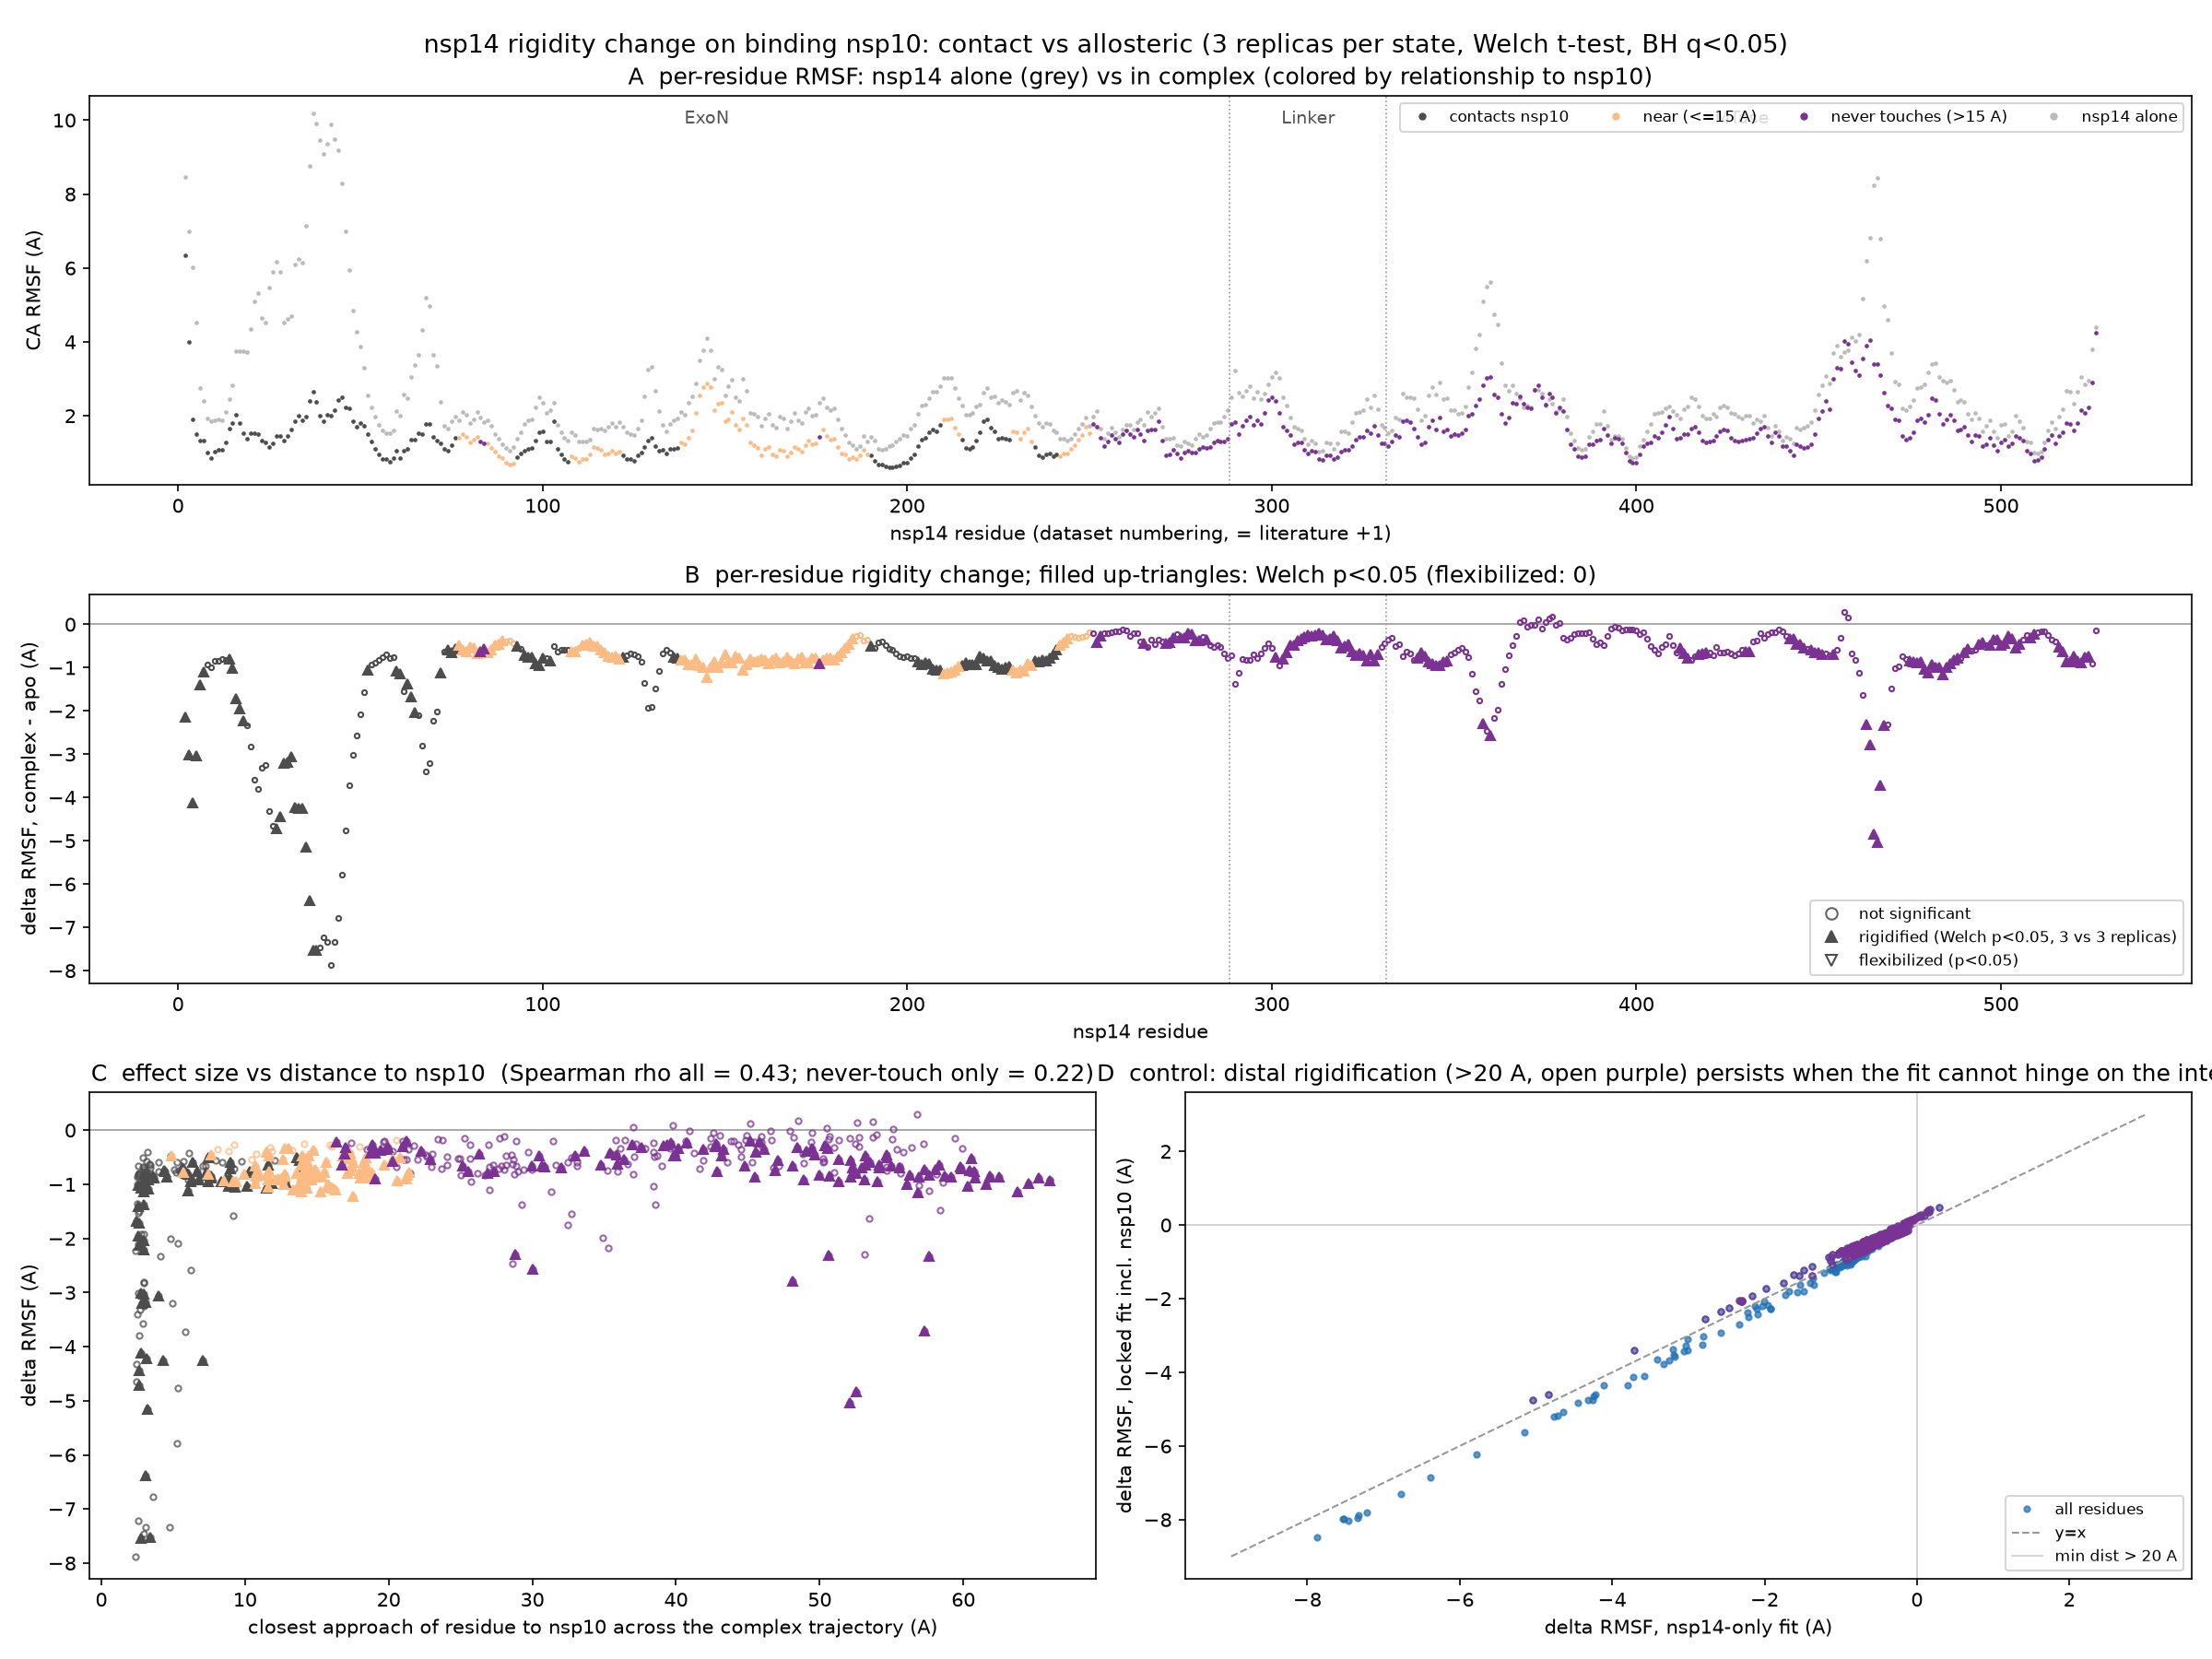

Full per-residue data with all statistics: `nsp14_allostery_per_residue.csv` (525 residues: RMSFs per state, Δ, Δ under locked fit, contact fractions, closest approach, window statistics, contact class); script `nsp14_allostery_analysis.py`.

In [3]:
%%ask
Which of the stabilised regions are actually in contact with nsp10, and which
never touch it? For any region that becomes more rigid without contacting
nsp10, how far is it from the binding interface, and how confident should I be
that the effect is real rather than noise?

## 4. Does the substrate add to it?

Now the third state. If nsp10 and RNA act on the same regions, they are
reinforcing one mechanism. If they act on different regions, the enzyme is
being tuned in two ways.

Analysis complete and lessons recorded. Here is the report.

## Short answer: No — RNA does not rigidify nsp14 further; it partially *reverses* nsp10's effect

Across the same per-replica analysis as before (3 × 2000 frames per state, 6000 frames each, nsp14-only CA fit, 525 residues), mean per-residue RMSF goes **apo 2.51 Å → +nsp10 1.52 Å → +nsp10+RNA 1.59 Å** . Adding RNA makes the complex very slightly *looser*, not more rigid — and the change is unevenly distributed: it goes in opposite directions in different parts of the protein.

| Domain | apo | +nsp10 | +nsp10+RNA | RNA's further change |
|---|---|---|---|---|
| ExoN (287 res) | 2.61 | 1.36 | 1.39 | +0.03 Å (no change) |
| Linker (43 res) | 2.05 | 1.46 | 1.34 | **−0.13 Å (further rigidified)** |
| MTase (195 res) | 2.46 | 1.78 | 1.95 | **+0.17 Å (partially de-rigidified)** |

The MTase loosening undoes about a quarter of nsp10's stabilization there, and both of the distal loops nsp10 had clamped drift back toward apo-like mobility: **Y466 loop 5.2 → 3.1 → 3.6 Å** , **481–484 loop 3.2 → 2.2 → 2.8 Å** . Sign test: 304/525 residues get looser (p = 3×10⁻⁴), but 84% of per-residue changes are < 0.25 Å — the reversal is real in aggregate, small per residue.

## Same regions or different ones? Different footprint, same general neighborhood

- **RNA binds a different patch than nsp10.** RNA contacts 49 nsp14 residues ever, 29 persistently (≥50% of 1200 sampled frames); nsp10 contacts 56 persistently. **The two persistent footprints overlap in only 2 residues.** RNA's contacts sit in the ExoN active-site cleft — D91/E93 (catalytic), W187/G190/F191, D274, plus the N-terminal tip (resid 2–10) and patches 100–105, 142–150, 246–254 — i.e. wrapped around the Mg²⁺ catalytic center (verified at frame 0: Mg chelated by D91/E192/W187). nsp10's interface is the flat ExoN face on the other side.
- **Where RNA does further rigidify, it tracks its own contacts** : Spearman ρ(contact fraction with RNA, rigidification) = +0.24, p = 2×10⁻⁸. RNA-contact residues tighten (1.38 → 1.31 Å; 64/98 rigidify), non-contact residues loosen (1.58 → 1.70 Å). The strongest single window is **142–148 (−0.37 Å)** , a persistent RNA-contact patch that nsp10 had also stabilized — the main point of overlap.
- **The one clear new rigidification is the interdomain linker (296–330)** , further stabilized by 0.13–0.36 Å — a region that touches neither nsp10 nor RNA. That is RNA's own allosteric contribution.

## Independent or cooperative? Neither additive nor cooperative — sub-additive with partial antagonism

The additivity test asks: at each 7-residue window, is RNA's further rigidification comparable to nsp10's (independent, additive), a fraction of it (sub-additive), ≥ all of it (cooperative), or nothing? Among the 69 windows where nsp10 actually moved something (Δ≥0.25 Å):

| Outcome | Windows |
|---|---|
| Cooperative (RNA's effect ≥ nsp10's) | **0** |
| Comparable/additive (75–100%) | 0 |
| Sub-additive (25–75%) | 7 |
| Negligible (<25%, mostly slight loosening) | 62 |

Supporting statistics: window-level **ρ(nsp10 effect, RNA effect) = −0.23** — mildly *anti*-correlated: the more nsp10 rigidified a window, the more RNA tends to give flexibility back; top-20 lists by each effect share only 5/20 windows; there are **zero** RNA-created stabilization sites where nsp10 had no effect. Locked-fit control (both complexes fitted on nsp14+nsp10 together, 655 CA): r = 0.97, slope 0.96 — the pattern is not a fitting artifact. nsp10 itself is untouched by RNA binding (mean RMSF 1.24 → 1.21 Å).

**Interpretation** : the two ligands do not cooperate mechanically. nsp10 clamps the ExoN domain from its interface face; RNA binds inside the ExoN catalytic cleft (a mostly disjoint patch), adds a little local stabilization there plus the linker — and releases part of nsp10's long-range clamp on the MTase. Functionally that reads as RNA binding shifting nsp14 back toward a more MTase-mobile state rather than freezing the whole enzyme.

## The comparison that supports it


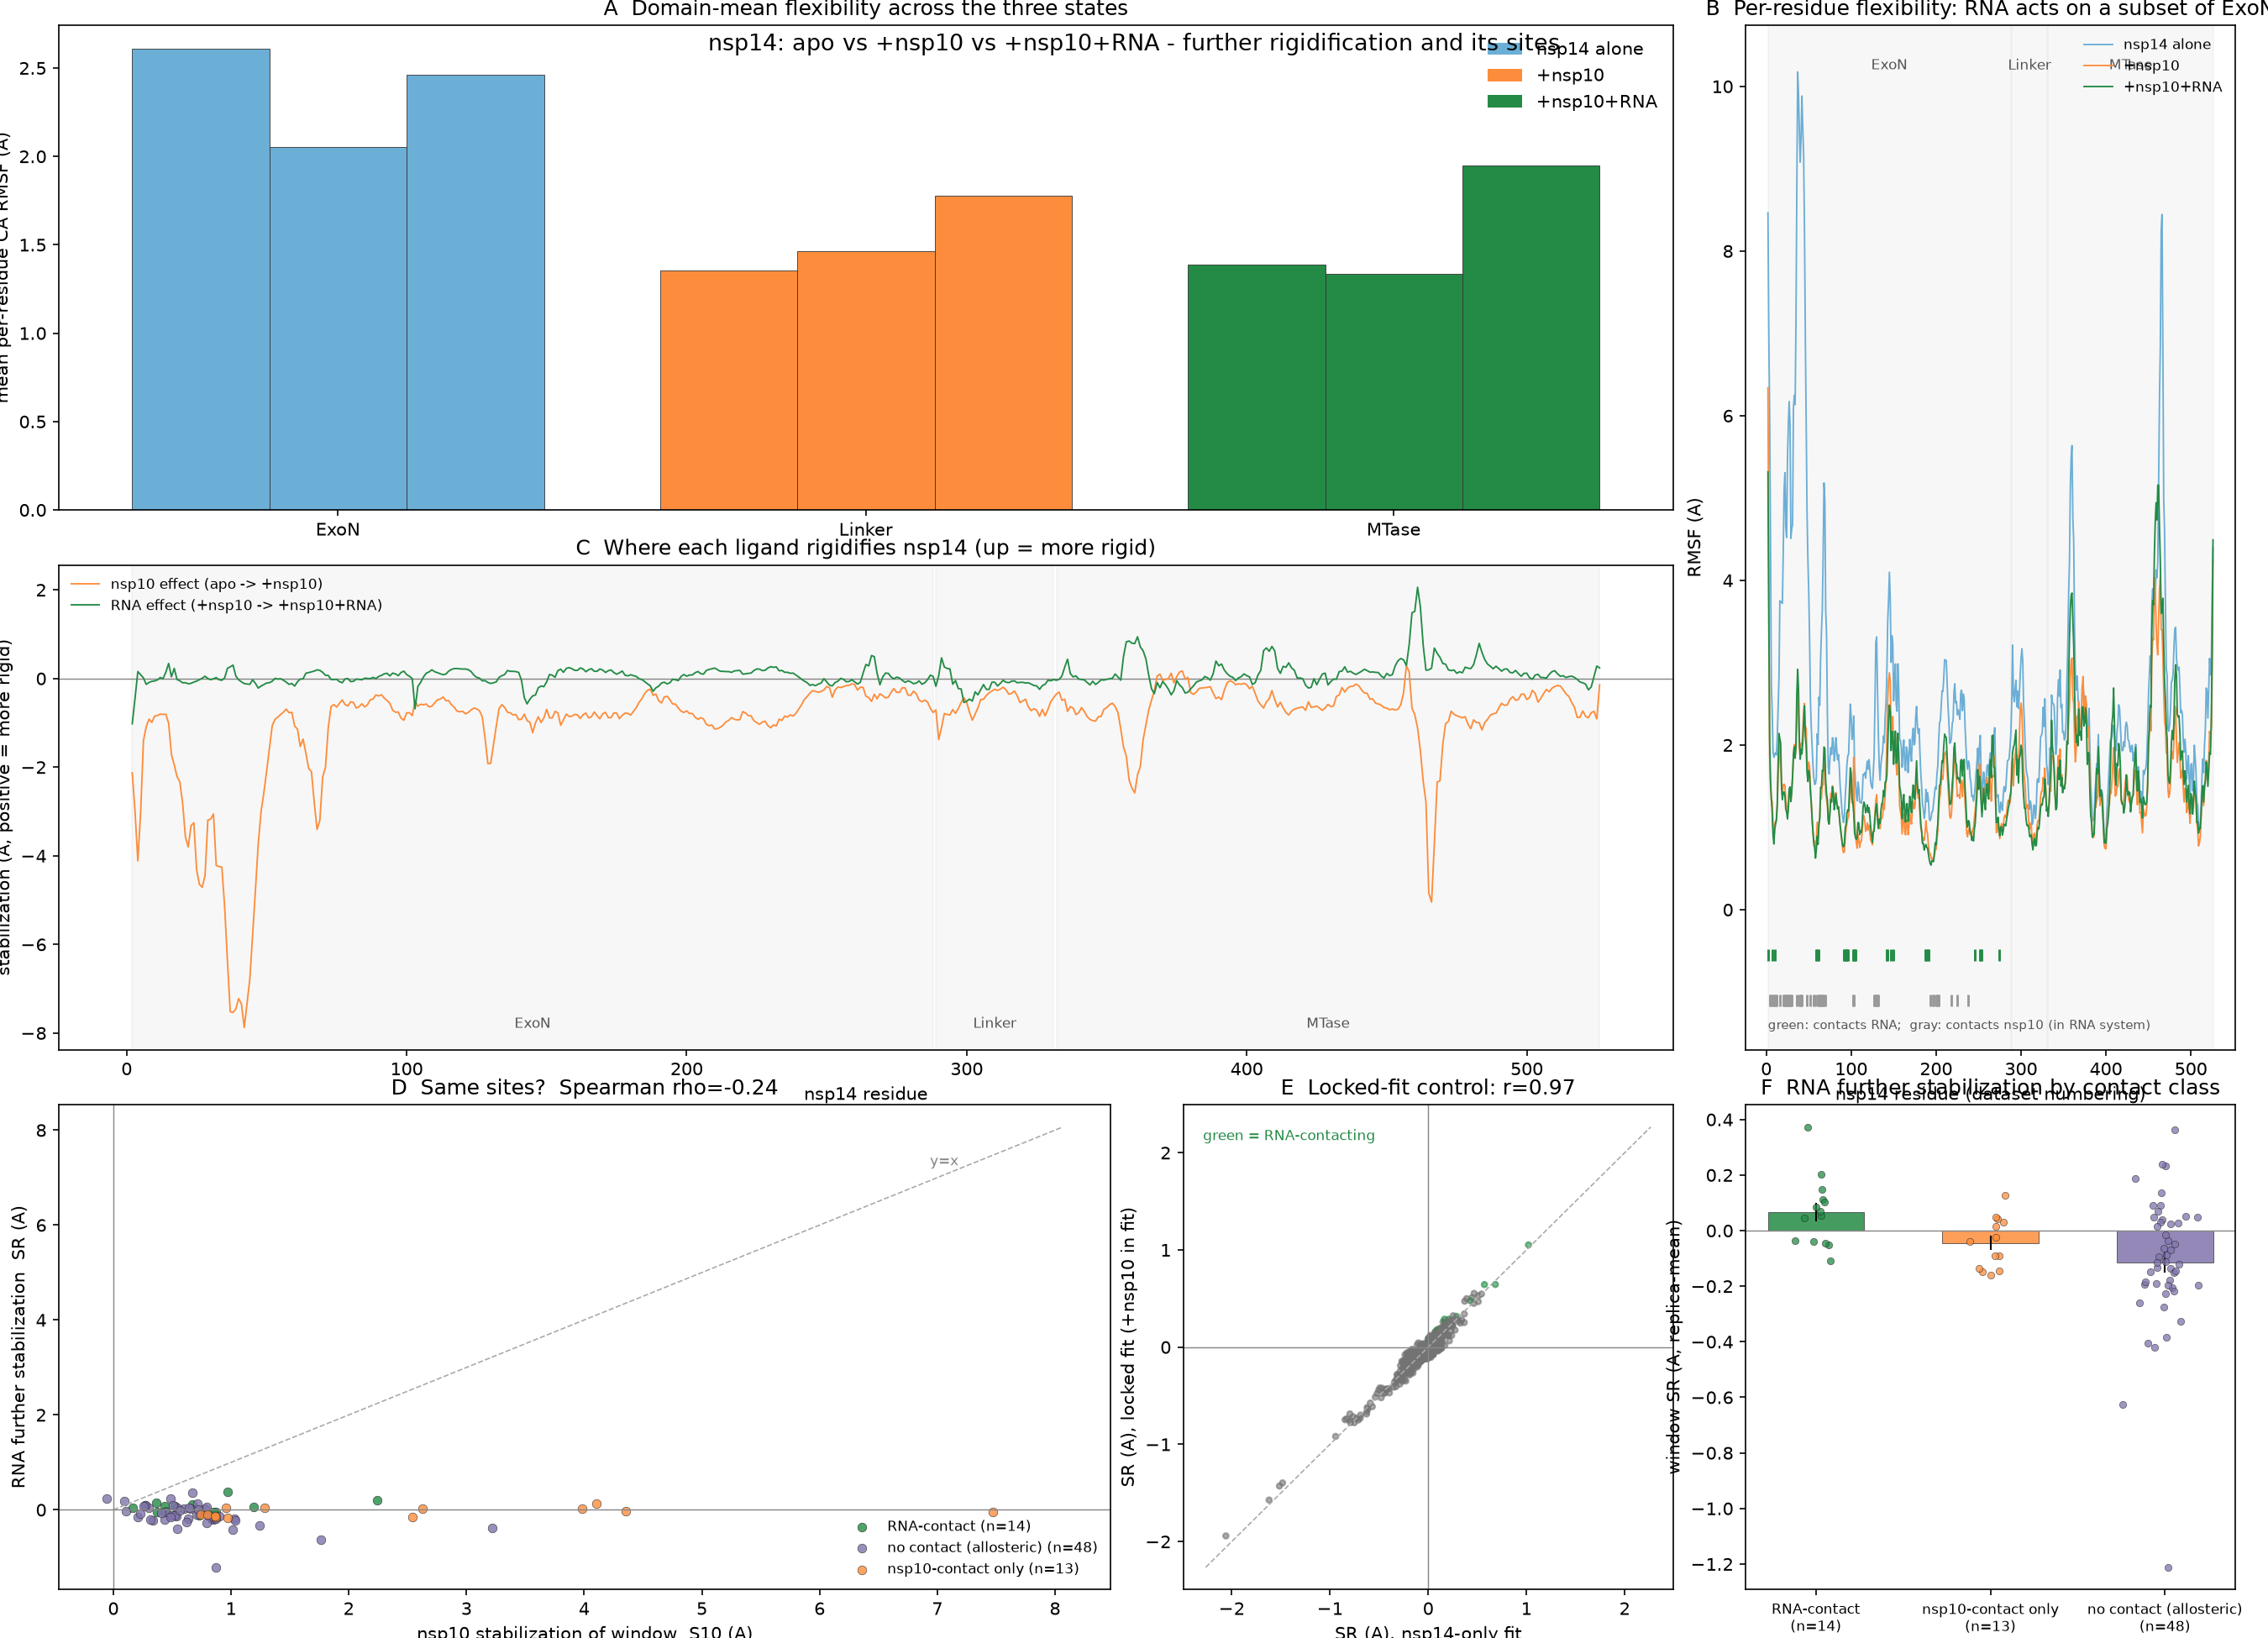

Panel A shows the domain three-state bars (the reversal is visible in MTase); B the per-residue three-state profile colored by contact class; C the mirror image — nsp10's per-residue rigidification (down) vs RNA's (up), showing RNA's effect confined to its contact patch and the linker; D the window scatter (ρ = −0.23, quadrant counts) making the antagonism visible; E the locked-fit control; F RNA's change by contact class.

## Confidence limits

- **Robust** : the direction of the global reversal (sign test over 525 residues), the contact-footprint disjointness (2/29 vs 56), the ρ = +0.24 contact-rigidification coupling, and ρ = −0.23 antagonism — all p < 10⁻³ and fit-control-stable.
- **Weaker** : individual window effects. With 3 vs 3 replicas, none of the top RNA windows passes even an uncorrected t-test (p ≈ 0.23–0.68), and Benjamini–Hochberg over 519 windows kills everything — the same power limit as the last cell. The linker rigidification and MTase loosening are consistent directionally across the domain means but their per-window magnitudes (0.1–0.4 Å) are near the 3-replica noise floor.
- **Still true from before** : frames not time, dry trajectories, and 3 × 2000-frame concatenations are descriptive, not converged ensembles.

Artifacts: `nsp14_rna_per_residue.csv` (525 residues: three-state RMSFs ± replica SD, S10/SR, contact fractions both ligands, locked-fit SR, window stats, additivity class), `nsp14_rna_windows.csv` (519 windows), `nsp14_fig4_rna_effect.png`, script `nsp14_rna_analysis.py`.

In [4]:
%%ask
Bring in the RNA-bound simulation. Does adding RNA rigidify nsp14 further, and
does it act on the same regions nsp10 already stabilised or on different ones?
Tell me whether the two effects look independent or cooperative, and show the
comparison that supports your answer.

## 5. Does any of this reach the catalytic machinery?

Flexibility changes at the surface are common and often mean little. The
question that matters for function is whether the active site itself is
affected. nsp14 carries structural zinc sites, and the exonuclease has a
catalytic centre.

All lessons recorded. Here is the report.

## Short answer: the chemistry of the zinc sites and the catalytic center is unchanged in all three states — what changes is their mobility, and the stabilization is *not* confined to surface loops: it reaches the core and the active site, just ~3× weaker there

## Zinc sites: same coordination in all three states, lower mobility in the complexes

All five zinc sites keep exactly the same four protein ligands at 100% occupancy (fraction of 300 frames with ligand < 3 Å) in every state they appear in — nsp10 never alters a single Zn ligand, and neither does RNA:

| Site (metal resid) | Coordinating residues (nsp14 numbering) | Apo metal RMSF | +nsp10 | +nsp10+RNA |
|---|---|---|---|---|
| Zn A (527) | C208, C211, C227, H230 | 2.68 Å | 1.64 Å | 1.90 Å |
| Zn B (528) | H258, C262, H265, C280 | 1.56 Å | 1.24 Å | 1.18 Å |
| Zn C (529) | C453, C478, C485, H488 | 3.24 Å | 1.81 Å | 2.08 Å |
| Zn D/E (nsp10's own, 660/661) | nsp10 C603/606/612/619 and C646/649/657/659 | — | 1.20 / 2.95 Å | 1.12 / 2.93 Å |

Coordination-number distributions are likewise state-invariant (means 4.6–6.8 counted atoms, SD ~0.7–1.0; this counts all atoms within 3 Å, not formal coordination geometry). None of the 12 Zn-liganding residues ever contacts nsp10 or RNA (contact fraction 0.00 for all of them) — so the sites change **because their neighborhoods quiet down, not because anything touches them** : the liganding residues rigidify by +0.2 to +1.1 Å (S10), and the metals' positional RMSF drops accordingly (site A −39%, site C −44% on complex formation). RNA neither strengthens nor disturbs any zinc site, and nsp10's own two zincs are identical in both complexes.

## Exonuclease active site: rigidified, but architecturally unchanged

The six catalytic residues (this dataset's numbering = literature +1) all gain rigidity with nsp10 from low apo baselines — none of them touch nsp10 (contact fraction 0.00):

| Residue | Apo RMSF | +nsp10 | +RNA | S10 | Burial (neighbours) |
|---|---|---|---|---|---|
| D91 | 1.06 | 0.69 | 0.76 | +0.37 | 193 (deep) |
| E93 | 1.37 | 0.87 | 0.99 | +0.50 | 153 |
| E192 | 1.11 | 0.69 | 0.60 | +0.42 | 177 |
| D244 | 1.32 | 0.99 | 0.83 | +0.33 | 169 |
| H269 | 2.21 | 1.86 | 1.72 | +0.35 | 91 |
| D274 | 1.21 | 0.98 | 0.97 | +0.23 | 176 |

But the site's **geometry is preserved** : across the 15 pairwise side-chain-centroid distances among these six residues, the largest shift is 0.97 Å apo→+nsp10 (median 0.23 Å) and 0.80 Å +nsp10→+RNA (median 0.23 Å) — sub-ångström. The active-site centroid's positional spread tightens modestly (apo 1.01–1.50 Å → complex 0.79–0.91 → RNA 0.69–1.01). So the catalytic machinery keeps its shape in all three states; nsp10 makes it fluctuate less around the same mean geometry. That is a real result: **no active-site rearrangement accompanies cofactor or RNA binding in these trajectories.**

The one genuine chemistry change is magnesium, and it comes with RNA: apo and +nsp10 carry a single catalytic Mg chelated by D91 + W187 + E192 (occupancy ≥0.73, CN ≈ 3.0–3.4). In the RNA-bound system that Mg keeps D91 + E192 but W187's contact drops below 50% — and a **second Mg²⁺ (resid 678) appears in the cleft, bridged by D91, D274, and an RNA phosphate** (occupancy 1.00). RNA thus brings an extra divalent cation that ties the catalytic residues to the substrate strand; the primary Mg's coordination count stays ~3.2–3.7 throughout.

## Surface vs core: graded, not confined

Burial (heavy-atom neighbours within 10 Å of each CA, apo, 50 frames) versus nsp10-induced rigidification S10:

| Class | n | Mean S10 | Rigidified |
|---|---|---|---|
| Surface (bottom burial quartile, ~88 neighbours) | 132 | +1.75 Å | 126/132 (p≈10⁻³⁰) |
| Intermediate | 261 | +0.83 Å | 258/261 (p≈10⁻⁷²) |
| Core (top quartile, ~179 neighbours) | 132 | +0.54 Å | **132/132** (p≈10⁻⁴⁰) |

Spearman ρ(burial, S10) = −0.38 (p = 1.4×10⁻¹⁹). Termini sit at the extremes: N-terminus (2–10) +1.95 Å, C-terminus (515–526) +0.70 Å. So stabilization is strongest on surface loops and the N-terminus — but the protein's core rigidifies uniformly (every single core residue), and the deeply buried catalytic residues (D91 at 193 neighbours is among the most buried residues in the protein) still gain +0.23 to +0.50 Å. The earlier per-residue picture stands: this is a global, distance-graded stabilization, not a surface-only patchwork.

## The figure


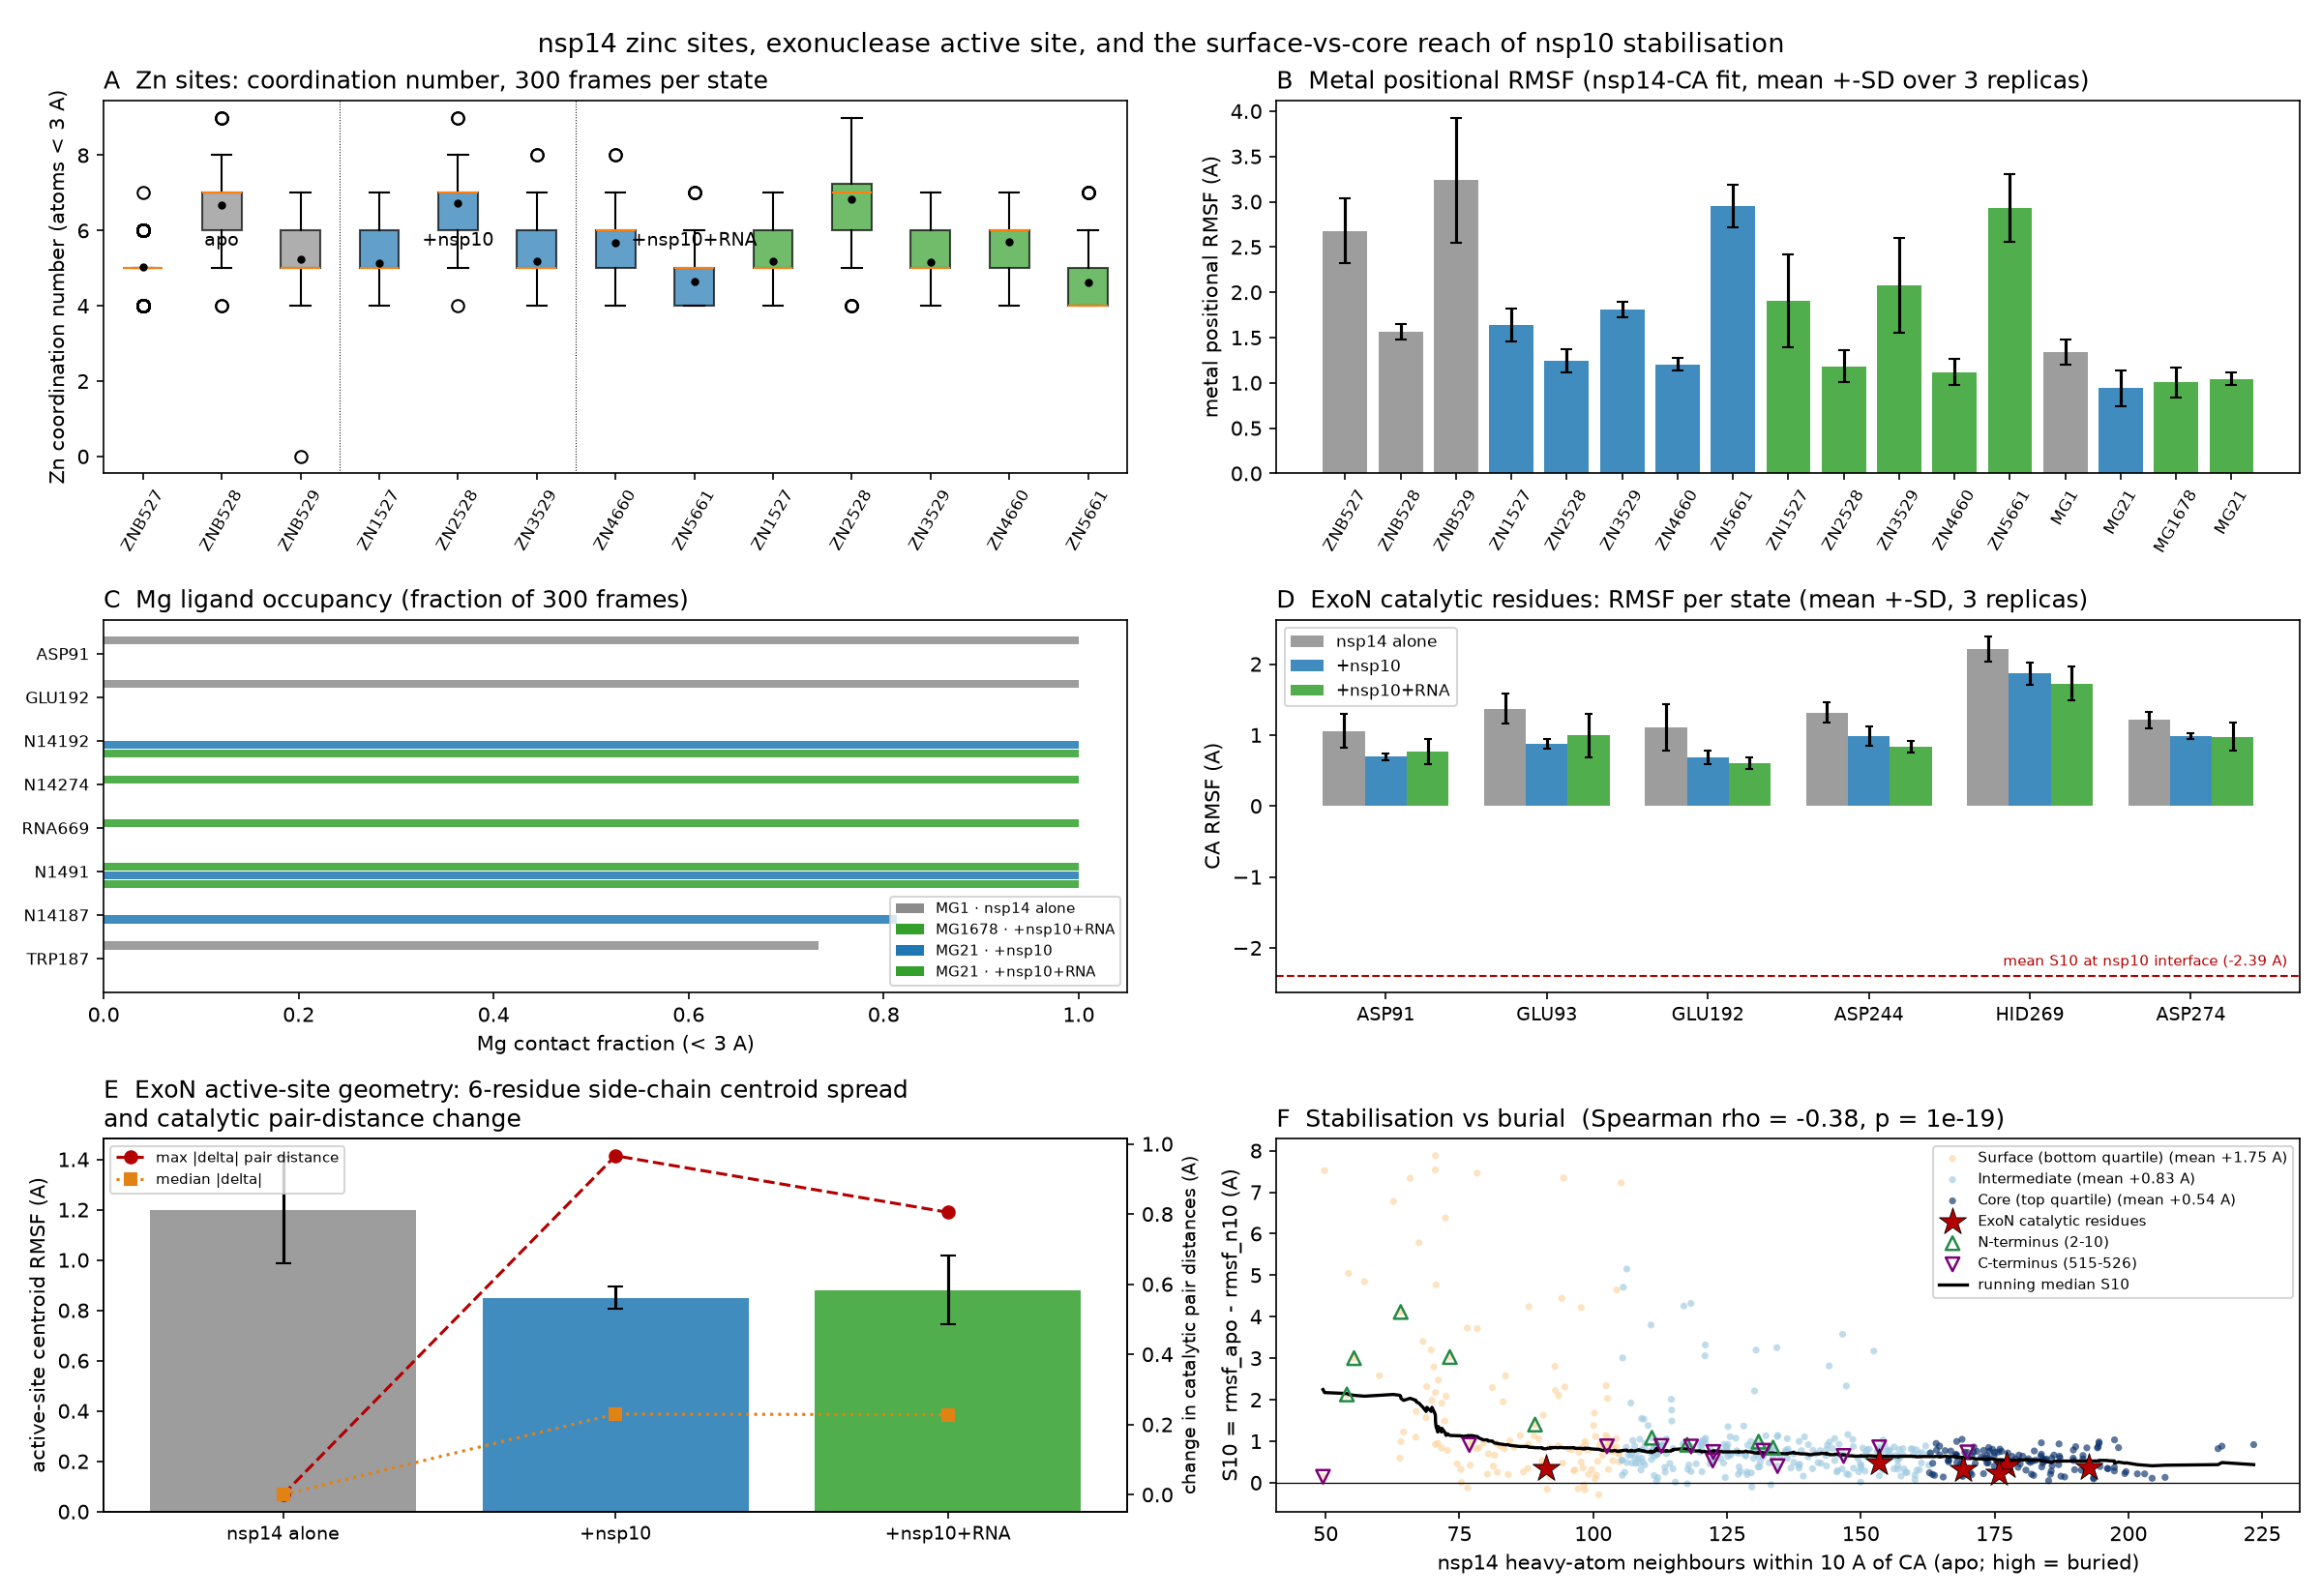

**A** Zn coordination-number distributions per site per state (nearly identical); **B** metal positional RMSF (nsp14's Zn sites drop ~40% on complexation; nsp10's Zn4/Zn5 unchanged by RNA); **C** Mg ligand occupancy — note the RNA-state columns where MG-678 appears with D91/D274/RNA-phosphate; **D** catalytic residues' RMSF across the three states (all three bars descend together, error bars are 3-replica SD); **E** active-site centroid spread and pair-distance shifts (sub-Å); **F** stabilization vs burial with catalytic residues starred, termini marked, and the running median showing the gradient.

Artifacts: `nsp14_zinc_sites.csv` (per-site ligands, CN, occupancies, metal RMSF), `nsp14_activesite_catalytic.csv`, `nsp14_burial_per_residue.csv` (525 residues with burial class, S10/SR, RMSFs), script `nsp14_zinc_activesite_analysis.py`.

## Caveats

- The cross-state Jaccard table printed by the script is meaningless for the complexes (their PSFs write chain labels as resnames, so ligand resnames read "N14208" etc.) — site correspondence above is established by coordinating resids, which match exactly (208/211/227/230, 258/262/265/280, 453/478/485/488).
- "Coordination number" here = atoms within 3.0 Å, a contact count, not formal coordination geometry; the ~5–6.8 values reflect extra nearby atoms, not hypercoordinate zinc.
- Metal RMSF is measured after a per-replica CA fit, so it reports motion relative to the protein frame, not lab-frame diffusion.
- Usual limits: dry trajectories, frames not time, 3 × 2000 frames per state — descriptive, not converged.

In [5]:
%%ask
Across the three states, does anything change around the zinc sites or in the
exonuclease active site, or is the stabilisation confined to surface loops and
termini? If the catalytic region is unchanged, say so plainly — that is a
result too.

## 6. Do the two domains move relative to each other?

nsp14 is two domains on one chain. Per-residue flexibility can fall while the
domains still swing against each other, so this needs its own measurement.

All lessons are recorded. Here is the report.

## Answer: neither closes nor opens — the interdomain arrangement is essentially invariant; what nsp10 changes is how much nsp14 *fluctuates*

## How interdomain motion was separated from internal motion

1. **Common frame first.** The RNA dataset's DCD is re-imaged across replica joins (raw block-start jumps of ~108.5 Å at frames 2000/4000, vs 1.6 Å max inside any block — an imaging artifact, not motion). Every block was therefore placed in one frame by per-frame Kabsch of nsp14's 525 CA atoms onto its own block start, plus one constant transform onto apo's first frame. Post-correction joins: 1.27/1.25 Å (RNA), 1.3 Å (others) — artifact gone, nothing chemical ever moves 108 Å.
2. **Interdomain geometry** = centroid distance and ExoN–linker–MTase angle, computed per frame from domain centroids (ExoN 2–287, linker 288–334, MTase 335–526). Centroids are insensitive to each domain's internal deformation.
3. **Internal motion** = coordinates re-centered *per domain* (removing every domain's rigid placement), then a joint PCA over all 9 blocks (3 states × 3 replicas × 2000 frames) in that domains-centered space. Between-state shape differences come from per-domain **mean-structure RMSDs** , never from projections of per-block-centered data (whose block means are zero by construction).
4. **Clean variance split** = per-frame Kabsch of each domain onto its own block-mean: what the rigid fit removes is interdomain rotation/translation; the residual is internal deformation. Within blocks only — no join contamination.

## The interdomain relationship does not change

| Measure (replica means ± SD) | apo | +nsp10 | +nsp10+RNA |
|---|---|---|---|
| ExoN–MTase centroid distance | 49.90 ± 0.23 Å | 50.37 ± 0.03 Å | 49.35 ± 0.33 Å |
| ExoN–linker–MTase angle | 124.0° ± 2.0 | 124.9° ± 1.1 | 124.1° ± 2.4 |
| Within-rep SD of the distance ("breathing") | 0.70 Å | 0.52 Å | 0.63 Å |

State-to-state shifts are **+0.47 Å** (apo→+nsp10, exact permutation p = 0.20) and **−1.02 Å** (+nsp10→+RNA, p = 0.10) on a 50 Å distance — ≤2%, neither significant at 3-vs-3. The angle does not move (p = 0.73 / 0.80). **There is no closing, no opening.** Even apo's famous 6 Å drift (cell 2) is *not* interdomain: its distance stays 49.9 ± 0.7 Å throughout — the drift is internal shape change plus domain reorientation, not a widening cleft.

## What does change: the fluctuation amplitude, everywhere

| Internal motion (joint-PC space) | apo | +nsp10 | +nsp10+RNA |
|---|---|---|---|
| Total internal variance | 4816 Å² | 1442 Å² (30% of apo) | 1696 Å² (35%) |
| PC1 / PC2 amplitude (SD) | 40.8 / 26.9 | 15.7 / 11.6 (0.38× / 0.43×) | 19.6 / 15.2 (1.25× / 1.31× of complex) |
| Per-domain mean-struct. RMSD vs apo | — | ExoN 2.63, linker 0.66, MTase 2.81 Å | ExoN 2.62, linker 1.15, MTase 2.97 Å |

- Every one of the top-10 collective modes is damped to **0.38–0.78×** by nsp10; the mode *directions* survive (RMSIP 0.58–0.73), so this is amplitude quenching, not a change of mechanism. PC1/PC2 loadings are collective (ExoN ~55–65% of weight, MTase ~half that, linker minor) — there is no single dominant hinge mode.
- RNA gives back **15–30%** of amplitude on most PCs (median ratio 1.18) — the same partial reversal seen in cell 4's RMSFs, now shown to live in the collective modes, not in any interdomain coordinate.
- Absolute variance split (within blocks): internal deformation 5.40 → 1.31 → 1.92 MÅ²/block (−76% with nsp10); rigid interdomain motion 4.23 → 1.57 → 1.94 MÅ² (−63%). Both are quenched; **internal more than interdomain** , which is why the interdomain *share* rises (43.9% → 54.4% → 56.7%) even as its absolute magnitude falls.
- Block clustering on RMSF profiles separates the states cleanly — and apo's replica 3 forms its own sub-cluster, matching its larger drift; the two complexes' replicas are homogeneous.

## Bottom line

Across apo → +nsp10 → +nsp10+RNA, nsp14 keeps the same two-domain architecture at the same separation (~50 Å) and angle (~124°): no closure, no opening, and the −1 Å RNA suggestion doesn't clear 3-replica noise. What the ligands change is **fluctuation** : nsp10 quenches internal collective motion to ~30% (and interdomain breathing from 0.70 to 0.52 Å), and RNA partially releases it (~+20%), consistently with the per-residue picture of the previous cells. The stabilization of cell 2 is therefore *not* an interdomain-clamping effect — it is a uniform damping of conformational fluctuation within a fixed domain arrangement.


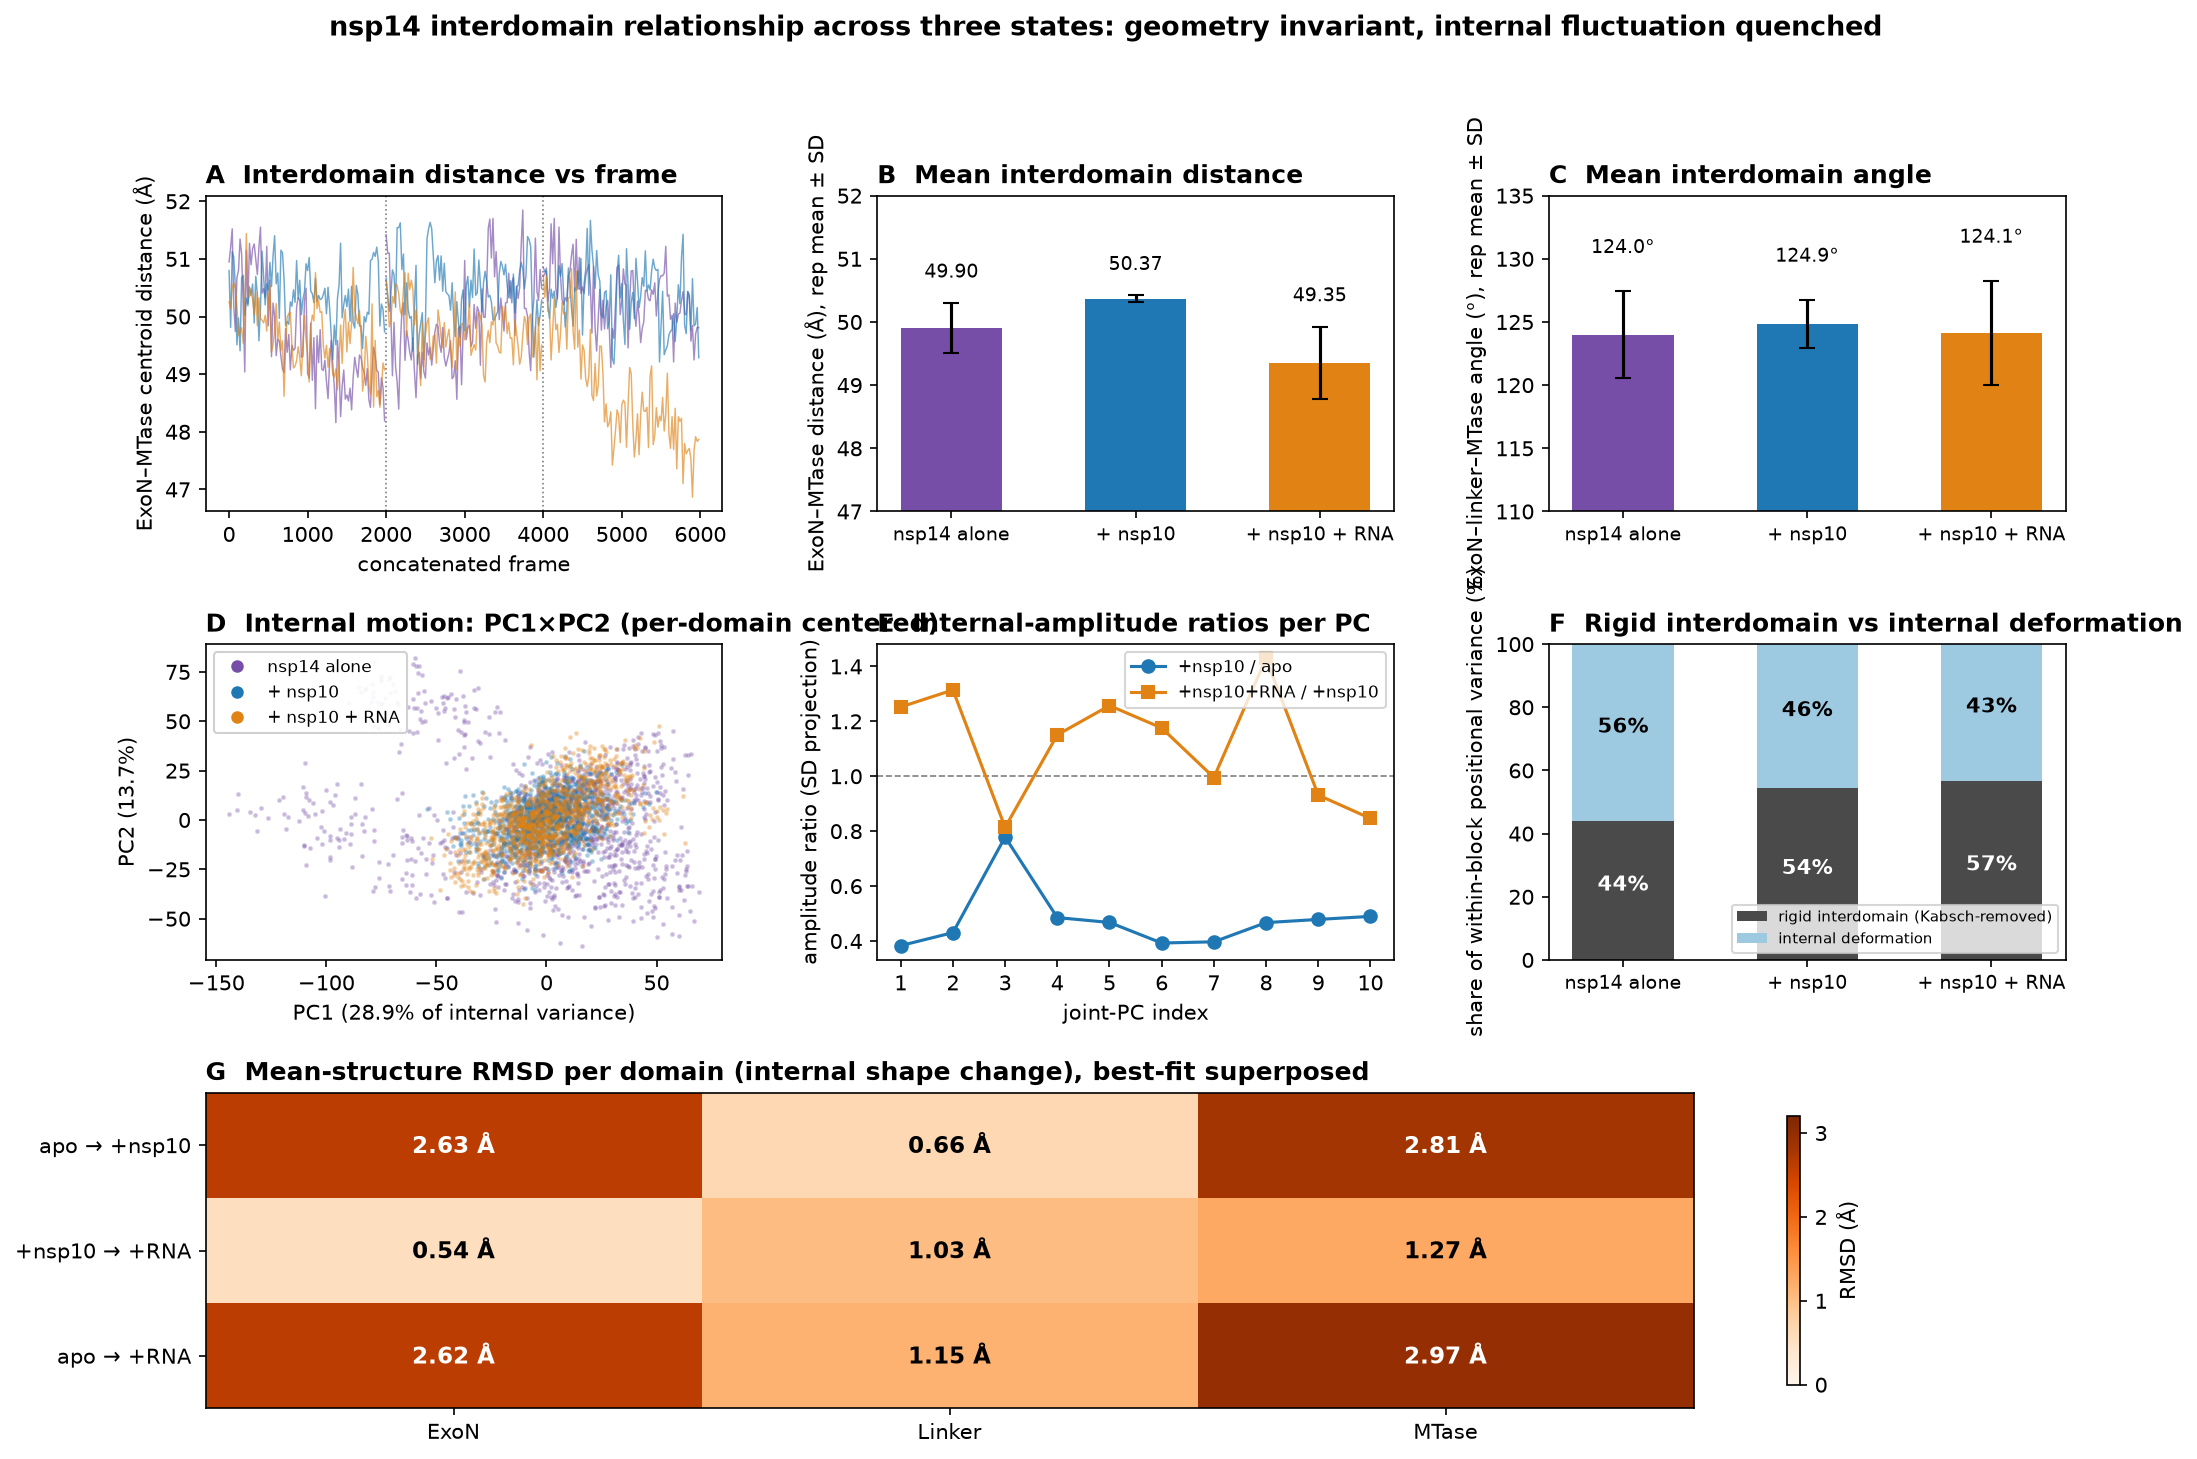

**Caveats** : 3 replicas per state — a ≤1 Å shift in the mean distance is below the detectable floor here (perm p ≥ 0.10), so "no change" means "no change larger than ~1–1.5 Å"; mean structures are not converged equilibrium averages; frames, not time; trajectories dry. Per-domain mean-structure RMSDs vs apo (~2.6–2.8 Å) partly reflect the different starting snapshots of the three systems rather than a state-specific conformation — the matched comparison is complex-vs-complex (0.5–1.3 Å).

Artifacts: `nsp14_pca_analysis.py`, `nsp14_fig6_interdomain.py`, `nsp14_pca_blocks.csv` (per-replica geometry + PC amplitudes), `nsp14_pca_modes.csv`, `nsp14_interdomain_geometry.csv` (per-frame traces), `nsp14_pca_core.npz` (projections, RMSIPs, variance splits), `nsp14_fig6_interdomain.png`.

In [6]:
%%ask
nsp14 has an exonuclease domain and a methyltransferase domain. Does the
relationship between them change across the three states — does the protein
close up, open out, or simply stop fluctuating? Show how you separated
interdomain motion from motion within each domain.

## 7. What does the series say?

The synthesis. Not a summary of the previous cells, but what the three states
together imply — and where the evidence is thin.

In [7]:
%%ask
Pulling the whole series together: what do these three simulations say about
how nsp14 is regulated by its partners? Where is the evidence strong, and where
is it weak given what these datasets can and cannot show? If any conclusion
rests on an assumption we have not tested, name it.

Numbers verified against the saved artifacts (`nsp14_rigidity_overall.csv`, `nsp14_pca_blocks.csv` — all headline values reproduce, including the per-replica spread). No new computation is needed; this is the synthesis of the series.

## What the three simulations say about nsp14 regulation

**nsp10 is a dynamic clamp, not a conformational switch.** It binds one face of the ExoN domain (56 persistent-contact residues, resid 4–238) and quenches fluctuation *everywhere*: mean per-residue RMSF drops 2.51 → 1.52 Å (−39%), backbone drift falls 6.06 → 2.25 Å, collective internal motion collapses to ~30% of apo, and 525-residue-wide sign tests leave **zero** residues more flexible. The effect is distance-graded from the interface (−2.39 Å at contacts → −0.73 Å at never-touching residues) and reaches the buried core (+0.54 Å, 132/132 residues), the zinc sites (metal RMSF −39/−44% with ligands unchanged), and the catalytic residues (+0.2 to +0.5 Å from low baselines). What it does **not** do: change the interdomain arrangement (centroid distance 49.9 → 50.4 Å, ≤2%, ns; angle flat at ~124°), compact the protein (Rg 31.6 → 31.8 Å), alter active-site geometry (sub-ångström pair-distance shifts), or change any zinc ligation. Regulation by nsp10 here is *damping*, not restructuring — nsp10 buys precision, not a new shape.

**RNA is not a second clamp — it rebalances.** Adding RNA to the complex rigidifies nothing further (1.52 → 1.59 Å, slightly looser; 304/525 residues gain flexibility, p = 3×10⁻⁴) and its footprint is nearly disjoint from nsp10's (2 overlapping residues out of 29 vs 56). Where RNA does act it follows its own contacts (ρ = +0.24): the catalytic cleft (D91/E93/W187/D274), patch 142–148, and — untouched by either ligand — the interdomain linker. Meanwhile it partially releases nsp10's distal clamp on the MTase (+0.17 Å, ~25% of nsp10's effect given back, including the Y466 and 481–484 loops) and the window-level correlation between nsp10's effect and RNA's is mildly *negative* (ρ = −0.23): zero cooperative windows, seven sub-additive, 62 negligible. The one chemical novelty is a second Mg²⁺ (resid 678) bridging D91, D274 and an RNA phosphate. Reading: substrate binding does not freeze the enzyme; it shifts the dynamic balance back toward MTase mobility while stapling the catalytic cleft locally.

**The regulation that is *not* seen is itself a result**: no closure or opening of the two-domain architecture in any state, no active-site rearrangement, no zinc rewiring, and PCA mode directions preserved (RMSIP 0.58–0.73) with only amplitudes damped. nsp14's partners regulate its fluctuations, not its architecture, in these trajectories.

## Where the evidence is strong vs weak

| Tier | Claim | Basis |
|---|---|---|
| **Strong** | nsp10 globally damps nsp14 fluctuation (~−40%) | 12,000 frames, all 6 blocks agree, effect ≫ replica spread |
| **Strong** | Damping is interface-centered and distance-graded | Contact fractions 1.00 at spine; ρ = 0.41–0.43, p ≤ 10⁻²⁵; survives locked-fit control |
| **Strong** | RNA adds no further rigidity; footprints nearly disjoint | Sign test 304/525; 2/29 overlap; both complexes 6000 frames |
| **Strong** | Interdomain geometry, active-site geometry, Zn ligation invariant | Permutation tests ns; sub-Å shifts; 100% ligand occupancy all states |
| **Moderate** | Distal (allosteric) rigidification sites — Y466 loop (−3.3 Å at 48 Å), 481–484 (50–59 Å), linker | All replica-pairs agree + fit-control-stable, but only uncorrected p<0.05; BH at 3-vs-3 kills everything, including the interface |
| **Moderate** | RNA's partial MTase reversal and ρ = −0.23 antagonism | Aggregate statistics robust; per-window magnitudes (0.1–0.4 Å) near the noise floor |
| **Weak/suggestive** | Linker stabilization by RNA; functional role of the second Mg²⁺; any allosteric *pathway* claim | Single-construct, no covariance/network analysis powered for it, no activity data |

One heterogeneity worth flagging honestly: the RNA reversal is driven partly by RNA replica 3 (PC1 amplitude 27.8 vs 13.9/13.6 for its siblings; centroid distance 48.7 vs 49.6/49.7) — the direction is consistent across replicas but its magnitude is not uniform. Apo shows the same pattern (its replica 3 sub-clustered separately).

## Untested assumptions the conclusions rest on

1. **Equal frame stride across the three datasets.** The DCD headers are unreliable (cpptraj reset them), so "2000 frames" may not represent equal simulated time per state. Every amplitude comparison in Å-per-frame inherits this; if the RNA stride were shorter, part of its "partial reversal" would be mechanical.
2. **The three blocks per dataset are independent replicas.** Block starts within a state sit 0.9–1.6 Å apart — near-identical starts, and the join signature is strong but circumstantial. If they are segments of one run, every "n = 3" test is really n = 1.
3. **Identical force-field parameters across files.** The apo PSF's placeholder zinc entries (ZNB, 12.0 Da) and zeroed charge column mean parameter equivalence cannot be verified from the files; apo's zinc-site mobility could partly reflect parameters, not physics.
4. **Dry trajectories preserve the relevant mechanics.** Interface water networks and bulk ions are stripped in all three; their contribution to interface rigidity is unquantified.
5. **The 16-mer RNA represents substrate-relevant binding.** One construct, one pose, sequence inferred from atom names — its antagonism with nsp10 may be pose-specific.
6. **Cross-state comparisons are meaningful despite unmatched starting snapshots** (frame-0 differences of 6.0/5.8/2.5 Å). Mitigated by fit controls and by leaning on RMSF/Rg rather than cross-fit RMSD, but not eliminable.
7. **"Rigidity → regulation → activity" is an interpretation, not a demonstration.** These data contain no activity measurements, binding energies, or kinetics; the functional reading (nsp10 activating ExoN by damping) is imported from literature, not shown here.
8. **Literature numbering = this numbering + 1** for catalytic/domain assignments — internally consistent across all three files, but the external mapping is assumed.

## What these datasets fundamentally cannot show

Binding free energies or affinities; rates, kinetics, or any time-denominated quantity; solvent-mediated mechanisms; whether damping *causes* functional activation (no perturbations — no interface mutants, no forced unbinding); convergence beyond 3×2000 frames per state; and anything about partners not simulated (e.g., nsp10's dynamics alone, other cofactors, longer viral RNA contexts).

**Bottom line** : across apo → +nsp10 → +nsp10+RNA, nsp14 is regulated purely through its fluctuation spectrum — nsp10 as a global, interface-graded, architecture-preserving damper; RNA as a local cleft-staple that partially releases nsp10's distal hold and imports a second catalytic Mg²⁺. The damping itself and the architectural non-events are as solid as 3×3 replicas get; the distal site assignments and the RNA antagonism are real-but-modest; and any claim that connects these dynamics to exonuclease *activity* rests on assumption 7, which nothing in these three files can test.

All evidence figures are in the cells above (`nsp14_fig1`–`fig6`), with per-residue and per-block data in the accompanying CSVs (`nsp14_rigidity_per_residue.csv`, `nsp14_allostery_per_residue.csv`, `nsp14_rna_per_residue.csv`, `nsp14_zinc_sites.csv`, `nsp14_burial_per_residue.csv`, `nsp14_pca_blocks.csv`).

## Reading the results

- **Three replicas, concatenated.** Agreement across replicas is reported where
  it matters, but these are not converged ensembles. Treat magnitudes as
  indicative and directions as the real finding.
- **Dry trajectories.** Water and ions were stripped before publication, so
  nothing here speaks to solvation, water-mediated contacts or ion binding.
- **Frames, not nanoseconds.** Frame intervals are not published for these
  files, so there are no rates or timescales in any answer.
- **The two complexes carry a topology quirk.** Their published PSF files leave
  the segment column blank and put the chain label in the residue-name field,
  so standard `protein` and `backbone` selections return nothing at all,
  silently. The skill carries the verified layout; this note is here because
  anyone repeating the analysis outside ARGUS will hit it.
- Everything fetched lives in `/tmp/amaro` and is cleared when the pod
  restarts.